# Individual-level instability of ICU risk predictions

## Notebook 2 of 3: development in MIMIC-IV, the bootstrap instability audit, and a real-data test of how well it works

This notebook develops in-hospital mortality models in MIMIC-IV with four model classes and asks three questions.

1. **How unstable are individual predictions and decisions** from models developed on the full MIMIC-IV cohort, and where (which risk range, which patients, which subgroups) is the instability concentrated?
2. **How does instability fall with development sample size**, and is the minimum sample size from the current analytic criteria enough for stable individual predictions and decisions?
3. **Does the standard bootstrap audit measure instability correctly?** The audit (Riley and Collins, 2023) is now recommended for every new model, yet its accuracy has so far been studied only in simulations. MIMIC-IV is large enough to draw truly independent development samples of the same size, so the *actual* between-sample instability can be observed directly for patients who were never used for development, and compared with what the bootstrap (in-sample, out-of-bag, new-patient) and an analytic Fisher-information approximation report.

| Notebook | Content |
|---|---|
| 1 | Cohorts, harmonised predictors, data quality (done) |
| **2 (this notebook)** | Model development, full-sample bootstrap audit (Riley-Collins levels 1 to 4), decision instability, internal validation, instability by subgroup (risk-standardised), the multiverse experiment (independent samples as ground truth) across seven development sizes, accuracy of instability estimators, sample size needed for individual-level and decision-level stability |
| 3 | External evaluation in eICU-CRD (205 hospitals): transport of instability, hospital-level heterogeneity, predictive multiplicity, sensitivity analyses, governance checks |

**Design principle.** Every source of randomness is seeded from one master seed; every expensive result is cached on disk and the notebook resumes where it stopped. The same independent development samples are used for all model classes, so model comparisons are paired.

**Data governance.** `outputs/part2/data` and `cache/part2` contain patient-level predictions and are protected by `.gitignore`. Figures and tables contain aggregates only.

## 0. Pre-specified analysis plan

| Element | Specification |
|---|---|
| Development data | MIMIC-IV main cohort from notebook 1 (first ICU stay per patient, one row per patient, so the ordinary bootstrap resamples patients) |
| Outcome | In-hospital death after the 24-h landmark |
| Predictors | 53 harmonised predictors from notebook 1; one missingness indicator per source variable that has missing values in the development sample (decided inside every fit) |
| Model classes | (1) unpenalised logistic regression, linear terms; (2) ridge logistic regression, penalty tuned by 5-fold cross-validation on log loss *inside every fit*; (3) random forest (300 trees, minimum leaf 20, square-root feature sampling); (4) histogram gradient boosting (300 iterations, learning rate 0.05, 15 leaves, minimum leaf 50, L2 1.0, native missing-value handling). Hyperparameters of (3) and (4) are fixed in advance so that the full model-building process can be repeated identically in every resample |
| Preprocessing | Median imputation, missingness indicators and standardisation are fitted inside every model fit (never on the full data), so their sampling variability is part of the measured instability |
| Decision thresholds | 0.10 (primary; close to the cohort risk, a screening threshold for senior review), 0.20 and 0.30 (escalation and goals-of-care discussion) |
| Full-sample audit | B = 200 bootstrap replicates of the complete model-building process on all MIMIC-IV patients; Riley-Collins levels 1 to 4; classification, calibration and decision-curve instability; Harrell, out-of-bag and .632+ internal validation. Each replicate model also predicts every eICU-CRD patient; those predictions are stored for notebook 3 and not examined here |
| Multiverse experiment | A fixed audit panel (20% of patients, at most 8,000) is never used for development. From the remaining pool, K = 30 independent development samples are drawn at each size n in {500, 1,000, 2,000, 4,000, minimum n from the analytic criteria, 8,000, 16,000} (sizes up to 55% of the pool); disjoint where the pool allows, otherwise random subsamples with a finite-population correction, validated against disjoint samples at the two largest sizes where at least two disjoint samples fit, and cross-checked against the analytic variance for logistic regression at every size |
| Ground truth | For each audit patient, the spread of predictions across the K independently developed models |
| Estimators compared with the truth | (a) standard bootstrap audit evaluated in the development sample; (b) out-of-bag bootstrap; (c) bootstrap models applied to the new (audit) patients; (d) analytic Fisher-information variance (logistic regression only), the basis of the recent individual-precision sample-size method. Bootstrap estimators use B = 100 within R = 5 of the K samples |
| Instability measures | Mean absolute prediction error (MAPE, instability index), root-mean-square individual SD, width of the individual 95% uncertainty interval, decision instability (share of models disagreeing with the majority decision; a patient is *decision-unstable* if more than 10% of models disagree), classification instability index (CII) |
| Equity | Risk-standardised instability ratio by sex, age band, race and ethnicity, ICU type and calendar period: observed instability divided by the instability expected from the patient's risk level alone |

In [1]:
import datetime as dt
import hashlib
import inspect
import json
import math
import os
import platform
import sys
import time
import warnings
import zlib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
import scipy
import sklearn
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from scipy.special import expit
from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

import cpmaudit
from cpmaudit import (ModelBuilder, StabilityAudit, StabilityResult, calibration_curve,
                      cox_snell_r2_from_c, minimum_sample_size_binary)
from cpmaudit.metrics import brier_score, calibration_intercept_slope, roc_auc
from cpmaudit.models import fit_quietly
from cpmaudit.resampling import BootstrapSampler

try:
    from joblib import parallel_config
except ImportError:  # joblib < 1.3
    from joblib import parallel_backend as parallel_config

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ENVIRONMENT = {
    "python": sys.version.split()[0], "platform": platform.platform(), "cpu_count": os.cpu_count(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "cpmaudit": cpmaudit.__version__,
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")

       python: 3.11.5
     platform: Windows-10-10.0.26300-SP0
    cpu_count: 14
        numpy: 2.4.6
       pandas: 3.1.1
        scipy: 1.17.1
 scikit-learn: 1.9.1
   matplotlib: 3.11.2
     cpmaudit: 0.1.0


## 1. Configuration

`STUDY_P2_PRESET=quick` runs a small version of every analysis (about 5 to 10 minutes) to check the set-up; the default `full` preset is the pre-specified analysis. Results of the two presets are cached separately.

In [2]:
PRESET = os.environ.get("STUDY_P2_PRESET", "full").lower()
assert PRESET in ("full", "quick"), "STUDY_P2_PRESET must be 'full' or 'quick'"
FULL = PRESET == "full"

CONFIG = {
    "preset": PRESET,
    "seed": 20261121,
    "models": ["lr", "ridge", "rf", "hgb"],
    "thresholds": [0.10, 0.20, 0.30],
    "primary_threshold": 0.10,
    "unstable_share": 0.10,             # a decision is unstable if more than 10% of models disagree with the majority
    "wide_interval": 0.10,              # an individual 95% interval wider than 10 percentage points is "wide"
    "b_full": 200 if FULL else 20,      # bootstrap replicates, full-sample audit
    "k_truth": 30 if FULL else 6,       # independent development samples per size
    "r_boot": 5 if FULL else 2,         # samples per size in which bootstrap estimators are run
    "b_curve": 100 if FULL else 10,     # bootstrap replicates per sample in the multiverse experiment
    "chunk": 10 if FULL else 5,         # bootstrap fits per parallel task
    "audit_fraction": 0.20,
    "audit_max": 8000,
    "ext_panel": 20000 if FULL else 3000,  # eICU-CRD patients predicted by every multiverse model (for notebook 3)
    "base_sizes": [500, 1000, 2000, 4000, 8000, 16000] if FULL else [200, 400, 800],
    "fpc_max_fraction": 0.55,           # largest sampled fraction of the pool for which the truth is reported
                                        # (0.55 keeps the pre-specified 16,000 when the pool is just under 32,000)
    "n_jobs": int(os.environ.get("STUDY_N_JOBS", max(1, (os.cpu_count() or 2) - 1))),
    "project_dir": Path(os.environ.get("STUDY_PROJECT_DIR", Path.cwd())),
    "force": os.environ.get("STUDY_FORCE_REBUILD", "0") == "1",
}
THRESHOLDS = tuple(CONFIG["thresholds"])
T0 = CONFIG["primary_threshold"]
N_JOBS = CONFIG["n_jobs"]

PROJECT = CONFIG["project_dir"]
P1 = PROJECT / "outputs" / "part1"
OUT = PROJECT / "outputs" / "part2"
DIRS = {name: OUT / name for name in ("figures", "tables", "data", "logs")}
CACHE = PROJECT / "cache" / f"part2_{PRESET}"
for folder in list(DIRS.values()) + [CACHE]:
    folder.mkdir(parents=True, exist_ok=True)
for private in (DIRS["data"], CACHE.parent):
    (private / ".gitignore").write_text("*\n", encoding="utf-8")

PRESET_KEY = hashlib.sha256(json.dumps({k: CONFIG[k] for k in (
    "seed", "b_full", "k_truth", "r_boot", "b_curve", "audit_fraction", "audit_max", "ext_panel", "base_sizes")},
    sort_keys=True).encode()).hexdigest()[:8]
print(f"Preset: {PRESET} (key {PRESET_KEY}); parallel workers: {N_JOBS}")
print("Project folder:", PROJECT.resolve())

Preset: full (key 01fb9742); parallel workers: 13
Project folder: C:\Users\kruta\Downloads


In [3]:
def stable_int(value):
    return zlib.crc32(str(value).encode()) & 0x7FFFFFFF


def seed_for(*keys):
    """Reproducible seed for any (model, size, replicate, ...) combination, independent of run order."""
    return int(np.random.SeedSequence([CONFIG["seed"], *[stable_int(k) for k in keys]]).generate_state(1)[0])


class Provenance:
    def __init__(self, path):
        self.path = Path(path)
        self.entries, self.steps, self.chain = [], [], "0" * 64
        self.started = dt.datetime.now(dt.timezone.utc)

    @staticmethod
    def sha256(path, block=1 << 20):
        digest = hashlib.sha256()
        with open(path, "rb") as fh:
            for chunk in iter(lambda: fh.read(block), b""):
                digest.update(chunk)
        return digest.hexdigest()

    def register(self, path, kind, description=""):
        file_hash = self.sha256(path)
        self.chain = hashlib.sha256((self.chain + file_hash).encode()).hexdigest()
        rel = str(Path(path).resolve().relative_to(PROJECT.resolve())) if str(Path(path).resolve()).startswith(str(PROJECT.resolve())) else str(path)
        self.entries.append({"file": rel, "kind": kind, "description": description, "sha256": file_hash,
                             "chain_sha256": self.chain, "bytes": Path(path).stat().st_size})

    def step(self, name, seconds):
        self.steps.append({"step": name, "seconds": round(seconds, 1)})

    def save(self, extra=None):
        payload = {"notebook": "part2_development_instability", "started_utc": self.started.isoformat(timespec="seconds"),
                   "finished_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                   "environment": ENVIRONMENT, "steps": self.steps, "files": self.entries,
                   "final_chain_sha256": self.chain, **(extra or {})}
        self.path.write_text(json.dumps(payload, indent=2, default=str), encoding="utf-8")
        return self.path


PROV = Provenance(DIRS["logs"] / "provenance_manifest.json")


class timed:
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        self.t0 = time.perf_counter()
        print(f"\n>>> {self.name}", flush=True)
        return self

    def __exit__(self, *exc):
        seconds = time.perf_counter() - self.t0
        PROV.step(self.name, seconds)
        print(f"<<< {self.name}: {seconds / 60:.1f} min", flush=True)


def save_table(df, name, description="", index=False):
    path = DIRS["tables"] / f"{name}.csv"
    df.to_csv(path, index=index)
    PROV.register(path, "table", description)
    return path


def save_json(obj, name, description="", folder="data"):
    path = DIRS[folder] / f"{name}.json"
    path.write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    PROV.register(path, "json", description)
    return path


def save_figure(fig, name, description=""):
    for ext in ("png", "pdf"):
        path = DIRS["figures"] / f"{name}.{ext}"
        fig.savefig(path, dpi=300 if ext == "png" else None, bbox_inches="tight", facecolor="white")
        PROV.register(path, f"figure-{ext}", description)
    plt.show()

### Figure style

Same conventions as notebook 1. Model classes have their own fixed colours (validated for colour-vision deficiency across all pairs) and markers, so they are never confused with the database colours of notebooks 1 and 3.

In [4]:
NEUTRAL, INK, INK2, GRID = "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLORS = {"lr": "#6250d6", "ridge": "#e87ba4", "rf": "#008300", "hgb": "#eda100"}
MODEL_MARKERS = {"lr": "o", "ridge": "s", "rf": "^", "hgb": "D"}
MODEL_LABELS = {"lr": "Logistic regression", "ridge": "Ridge logistic regression",
                "rf": "Random forest", "hgb": "Gradient boosting"}
MODEL_SHORT = {"lr": "LR", "ridge": "Ridge", "rf": "RF", "hgb": "GBM"}
DIVERGING = LinearSegmentedColormap.from_list("instability", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": NEUTRAL, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 2, "pdf.fonttype": 42, "ps.fonttype": 42,
})


def panel_label(ax, letter):
    ax.set_title(f"{letter}   {ax.get_title(loc='left')}", loc="left")


def plain_log_axis(axis, subs=(1.0, 2.0, 5.0), fmt="{:,.0f}"):
    axis.set_major_locator(matplotlib.ticker.LogLocator(base=10, subs=subs))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fmt.format(v)))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())


def model_handles(models, line=True):
    return [Line2D([0], [0], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], lw=2 if line else 0,
                   markersize=6, label=MODEL_LABELS[m]) for m in models]

## 2. Data from notebook 1

In [5]:
SPEC = json.loads((P1 / "data" / "analysis_spec.json").read_text(encoding="utf-8"))
P1_SUMMARY = json.loads((P1 / "data" / "study_summary.json").read_text(encoding="utf-8"))
PRED = SPEC["predictors"]
OUTCOME = SPEC["outcomes"]["primary"]
GROUPS = SPEC["missing_indicator_groups"]
GROUP_INDEX = [[PRED.index(c) for c in cols] for cols in GROUPS.values()]
GROUP_NAMES = list(GROUPS)

dev = pd.read_parquet(PROJECT / SPEC["datasets"]["development_main"]).reset_index(drop=True)
ext = pd.read_parquet(PROJECT / SPEC["datasets"]["external_main"]).reset_index(drop=True)
assert len(dev) == P1_SUMMARY["cohorts"]["mimic_main"]["stays"], "MIMIC-IV main cohort differs from notebook 1"
assert len(ext) == P1_SUMMARY["cohorts"]["eicu_main"]["stays"], "eICU-CRD main cohort differs from notebook 1"

dev["age_band"] = pd.cut(dev["age"], [0, 49, 64, 79, 200], labels=["18-49", "50-64", "65-79", "80+"]).astype(str)
ext["age_band"] = pd.cut(ext["age"], [0, 49, 64, 79, 200], labels=["18-49", "50-64", "65-79", "80+"]).astype(str)
SUBGROUP_DIMS = {"sex": "Sex", "age_band": "Age (years)", "race_group": "Race and ethnicity",
                 "care_unit_group": "ICU type", "year_group": "Calendar period"}

X_dev = dev[PRED].to_numpy(dtype=np.float64)
y_dev = dev[OUTCOME].to_numpy(dtype=np.int64)
X_ext = ext[PRED].to_numpy(dtype=np.float64)
y_ext = ext[OUTCOME].to_numpy(dtype=np.int64)
N_DEV = len(y_dev)
PREV = y_dev.mean()

print(f"MIMIC-IV development: {N_DEV:,} patients, {y_dev.sum():,} deaths ({PREV:.2%}); {len(PRED)} predictors, "
      f"{sum(dev[c].isna().any().any() for c in GROUPS.values())} source variables with missing values")
print(f"eICU-CRD (stored predictions only, analysed in notebook 3): {len(y_ext):,} patients, {y_ext.sum():,} deaths")

MIMIC-IV development: 39,966 patients, 3,888 deaths (9.73%); 53 predictors, 22 source variables with missing values
eICU-CRD (stored predictions only, analysed in notebook 3): 94,114 patients, 8,753 deaths


## 3. Model classes

The preprocessing step creates **one** missingness indicator per source variable (the minimum, maximum and mean of a variable are missing together, so per-column indicators would be duplicates). Which variables get an indicator is decided from the data each model is fitted on, exactly as an analyst would do it.

In [6]:
class GroupedImputer(BaseEstimator, TransformerMixin):
    """Median imputation, one missingness indicator per group of columns, optional standardisation."""

    def __init__(self, groups=None, scale=True):
        self.groups = groups
        self.scale = scale

    def _build(self, X):
        miss = np.isnan(X)
        Xi = np.where(miss, self.medians_, X)
        if self.indicator_groups_:
            Xi = np.column_stack([Xi] + [miss[:, g].any(axis=1).astype(float) for g in self.indicator_groups_])
        return Xi

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X, axis=0)
        self.medians_ = np.where(np.isnan(med), 0.0, med)
        self.indicator_groups_ = [list(g) for g in (self.groups or []) if np.isnan(X[:, g]).any()]
        if self.scale:
            Z = self._build(X)
            self.mean_ = Z.mean(axis=0)
            sd = Z.std(axis=0)
            self.sd_ = np.where(sd > 0, sd, 1.0)
        return self

    def transform(self, X):
        Z = self._build(np.asarray(X, dtype=float))
        return (Z - self.mean_) / self.sd_ if self.scale else Z


_lrcv = inspect.signature(LogisticRegressionCV).parameters
SK_VERSION = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
RIDGE_KW = {}
if "l1_ratios" in _lrcv and SK_VERSION >= (1, 8):
    RIDGE_KW["l1_ratios"] = (0.0,)
if "use_legacy_attributes" in _lrcv:
    RIDGE_KW["use_legacy_attributes"] = False


def make_estimator(name):
    if name == "lr":
        return Pipeline([("prep", GroupedImputer(GROUP_INDEX)), ("model", LogisticRegression(C=np.inf, max_iter=10000))])
    if name == "ridge":
        return Pipeline([("prep", GroupedImputer(GROUP_INDEX)),
                         ("model", LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                                        scoring="neg_log_loss", max_iter=10000, **RIDGE_KW))])
    if name == "rf":
        return Pipeline([("prep", GroupedImputer(GROUP_INDEX, scale=False)),
                         ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=1))])
    if name == "hgb":
        return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=50,
                                              l2_regularization=1.0, early_stopping=False)
    raise ValueError(name)


MODELS = {m: ModelBuilder(make_estimator(m)) for m in CONFIG["models"]}
MODEL_SPEC = pd.DataFrame([
    {"model": MODEL_LABELS["lr"], "preprocessing": "median imputation, grouped missingness indicators, standardisation",
     "estimator": "LogisticRegression, no penalty", "tuning": "none"},
    {"model": MODEL_LABELS["ridge"], "preprocessing": "as logistic regression",
     "estimator": "LogisticRegressionCV, L2", "tuning": "C over 13 values 1e-4 to 1e2, 5-fold CV, log loss, inside every fit"},
    {"model": MODEL_LABELS["rf"], "preprocessing": "median imputation, grouped missingness indicators",
     "estimator": "RandomForestClassifier: 300 trees, min_samples_leaf 20, max_features sqrt", "tuning": "fixed in advance"},
    {"model": MODEL_LABELS["hgb"], "preprocessing": "none (native missing-value handling)",
     "estimator": "HistGradientBoostingClassifier: 300 iterations, learning rate 0.05, 15 leaves, min_samples_leaf 50, L2 1.0",
     "tuning": "fixed in advance; no early stopping"},
])
save_table(MODEL_SPEC, "table_p2_model_specification", "Model classes, preprocessing and hyperparameters")
display(MODEL_SPEC)

,model,preprocessing,estimator,tuning
0,Logistic regression,"median imputation, grouped missingness indicat...","LogisticRegression, no penalty",none
1,Ridge logistic regression,as logistic regression,"LogisticRegressionCV, L2","C over 13 values 1e-4 to 1e2, 5-fold CV, log l..."
2,Random forest,"median imputation, grouped missingness indicators","RandomForestClassifier: 300 trees, min_samples...",fixed in advance
3,Gradient boosting,none (native missing-value handling),HistGradientBoostingClassifier: 300 iterations...,fixed in advance; no early stopping


In [7]:
# Smoke test: every model fits and predicts on a small sample before any long computation starts.
rng = np.random.default_rng(seed_for("smoke"))
idx = rng.choice(N_DEV, size=min(1500, N_DEV), replace=False)
for m, builder in MODELS.items():
    fitted, n_conv = fit_quietly(builder, X_dev[idx], y_dev[idx], random_state=1)
    p = builder.predict_risk(fitted, X_dev[:200])
    assert np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1
    print(f"{MODEL_LABELS[m]:<28} ok  (risk range {p.min():.3f} to {p.max():.3f}; convergence warnings {n_conv})")

Logistic regression          ok  (risk range 0.000 to 0.978; convergence warnings 0)
Ridge logistic regression    ok  (risk range 0.000 to 0.943; convergence warnings 0)
Random forest                ok  (risk range 0.001 to 0.408; convergence warnings 0)
Gradient boosting            ok  (risk range 0.000 to 0.940; convergence warnings 0)


## 4. Compute plan

Each model is timed once on the full development data and on 2,000 patients; fit time is interpolated on the log scale for the other sizes. The estimate assumes `N_JOBS` parallel workers.

In [8]:
def fit_seconds(builder, n, seed=0):
    rng = np.random.default_rng(seed_for("bench", n))
    idx = rng.choice(N_DEV, size=min(n, N_DEV), replace=False)
    t0 = time.perf_counter()
    fitted, _ = fit_quietly(builder, X_dev[idx], y_dev[idx], random_state=seed)
    builder.predict_risk(fitted, X_dev[:8000])
    return time.perf_counter() - t0


small = min(2000, N_DEV // 2)
BENCH = {}
for m, builder in MODELS.items():
    BENCH[m] = (fit_seconds(builder, small), fit_seconds(builder, N_DEV))


def t_fit(m, n):
    ts, tf = BENCH[m]
    e = math.log(max(tf, 1e-3) / max(ts, 1e-3)) / math.log(N_DEV / small) if N_DEV > small else 1.0
    return ts * (n / small) ** e


n_audit_planned = min(CONFIG["audit_max"], int(CONFIG["audit_fraction"] * N_DEV))
sizes_planned = [s for s in CONFIG["base_sizes"] if s <= (N_DEV - n_audit_planned) * CONFIG["fpc_max_fraction"]] + [5000]
rows = []
for m in MODELS:
    full = (CONFIG["b_full"] + 1) * BENCH[m][1] * 1.6  # prediction of eICU-CRD and calibration per replicate
    curve = sum((CONFIG["k_truth"] + CONFIG["r_boot"] * CONFIG["b_curve"]) * t_fit(m, n) * 1.3 for n in sizes_planned)
    rows.append({"model": MODEL_LABELS[m], "fit_2000_s": round(BENCH[m][0], 2), "fit_full_s": round(BENCH[m][1], 2),
                 "full_audit_min": full / N_JOBS / 60 / 0.85, "multiverse_min": curve / N_JOBS / 60 / 0.85})
PLAN = pd.DataFrame(rows)
PLAN["total_min"] = PLAN["full_audit_min"] + PLAN["multiverse_min"]
display(PLAN.round(1))
print(f"Estimated total compute time with {N_JOBS} workers: about {PLAN['total_min'].sum():.0f} minutes "
      f"(interruptions are safe: finished parts are cached).")

,model,fit_2000_s,fit_full_s,full_audit_min,multiverse_min,total_min
0,Logistic regression,0.1,0.7,0.3,1.1,1.4
1,Ridge logistic regression,1.0,6.0,2.9,11.7,14.6
2,Random forest,3.6,79.5,38.5,71.0,109.6
3,Gradient boosting,1.5,2.8,1.4,12.5,13.8


Estimated total compute time with 13 workers: about 139 minutes (interruptions are safe: finished parts are cached).


## 5. Full-sample development and bootstrap instability audit

For each model class the complete model-building process is run on all MIMIC-IV patients (the "original" model) and repeated in 200 bootstrap samples (`cpmaudit.StabilityAudit`). Each bootstrap model predicts every development patient (Riley-Collins audit) and every eICU-CRD patient (stored for notebook 3). Results are written once and reloaded on later runs.

In [9]:
def full_paths(m):
    stem = f"full_audit_{m}_{PRESET_KEY}"
    return {"npz": DIRS["data"] / f"{stem}.npz", "metrics": DIRS["data"] / f"{stem}_replicates.parquet",
            "json": DIRS["data"] / f"{stem}.json"}


def load_full(m):
    paths = full_paths(m)
    arrays = np.load(paths["npz"])
    meta = json.loads(paths["json"].read_text(encoding="utf-8"))
    return StabilityResult(
        y=y_dev, p_original=arrays["p"].astype(np.float64), P=arrays["P"], thresholds=THRESHOLDS, interval_level=0.95,
        replicate_metrics=pd.read_parquet(paths["metrics"]), performance_apparent=meta["performance_apparent"],
        config=meta["config"], failures=meta["failures"], flip_tolerance=CONFIG["unstable_share"],
        wide_interval=CONFIG["wide_interval"])


def run_full_audit(m):
    paths = full_paths(m)
    if CONFIG["force"] or not all(p.exists() for p in paths.values()):
        audit = StabilityAudit(MODELS[m], n_bootstrap=CONFIG["b_full"], bootstrap="simple", thresholds=THRESHOLDS,
                               optimism=True, n_jobs=N_JOBS, random_state=seed_for(m, "full"), smooth_calibration=True)
        res = audit.run(X_dev, y_dev, X_external=X_ext, y_external=y_ext)
        np.savez_compressed(paths["npz"], p=res.p_original, P=res.P.astype(np.float32),
                            p_ext=res.p_original_external, P_ext=res.P_external.astype(np.float32))
        res.replicate_metrics.to_parquet(paths["metrics"], index=False)
        meta = {"performance_apparent": res.performance_apparent,
                "performance_external_original": res.performance_external_original,
                "config": res.config, "failures": res.failures}
        paths["json"].write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")
        for kind, p in paths.items():
            PROV.register(p, f"full-audit-{kind}", f"Full-sample bootstrap audit, {MODEL_LABELS[m]}")
        del res
    return load_full(m)


FULL_RES = {}
for m in CONFIG["models"]:
    with timed(f"Full-sample audit: {MODEL_LABELS[m]}"):
        FULL_RES[m] = run_full_audit(m)
        cfg = FULL_RES[m].config
        print(f"   {cfg['n_bootstrap_effective']} of {cfg['n_bootstrap_requested']} replicates; "
              f"failures {cfg['n_failed']}; convergence warnings {cfg['convergence_warnings']}; "
              f"run time {cfg['runtime_seconds'] / 60:.1f} min")


>>> Full-sample audit: Logistic regression
   200 of 200 replicates; failures 0; convergence warnings 0; run time 0.8 min
<<< Full-sample audit: Logistic regression: 0.0 min

>>> Full-sample audit: Ridge logistic regression
   200 of 200 replicates; failures 0; convergence warnings 0; run time 3.2 min
<<< Full-sample audit: Ridge logistic regression: 0.0 min

>>> Full-sample audit: Random forest
   200 of 200 replicates; failures 0; convergence warnings 0; run time 25.5 min
<<< Full-sample audit: Random forest: 0.0 min

>>> Full-sample audit: Gradient boosting
   200 of 200 replicates; failures 0; convergence warnings 0; run time 4.2 min
<<< Full-sample audit: Gradient boosting: 0.0 min


### Out-of-bag view of the same replicates

The standard audit evaluates every bootstrap model in the whole development sample, so about 63% of the patients it is evaluated on were used to fit it. The out-of-bag (OOB) version uses, for each patient, only the bootstrap models that did not see that patient. The bootstrap rows are regenerated exactly from the stored replicate seeds; a check against the stored apparent mean risk confirms the regeneration.

In [10]:
EPS = 1e-4


def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def spread_summary(P, ref=None, use=None):
    """Per-patient spread of an ensemble of predictions P (models x patients).
    ref: predictions of the 'current' model (for MAPE and CII); use: boolean mask of models to use per patient."""
    P = np.asarray(P, dtype=np.float64)
    w = np.ones_like(P) if use is None else use.astype(np.float64)
    m = w.sum(axis=0)
    ms = np.maximum(m, 1.0)
    mean = (w * P).sum(axis=0) / ms
    var = (w * (P - mean) ** 2).sum(axis=0) / np.maximum(m - 1, 1.0)
    L = logit(P)
    lmean = (w * L).sum(axis=0) / ms
    lsd = np.sqrt((w * (L - lmean) ** 2).sum(axis=0) / np.maximum(m - 1, 1.0))
    out = {"n_models": m, "mean": mean, "sd": np.sqrt(var), "logit_mean": lmean, "logit_sd": lsd}
    if ref is not None:
        out["mape"] = (w * np.abs(P - ref[None, :])).sum(axis=0) / ms
        for t in THRESHOLDS:
            out[f"cii@{t:g}"] = (w * ((P >= t) != (ref >= t)[None, :])).sum(axis=0) / ms
    for t in THRESHOLDS:
        above = (w * (P >= t)).sum(axis=0) / ms
        out[f"minority_emp@{t:g}"] = np.minimum(above, 1 - above)
    return add_logit_normal(out)


def add_logit_normal(out):
    """Decision instability and interval width from a normal approximation on the logit scale."""
    mu, s = out["logit_mean"], np.maximum(out["logit_sd"], 1e-9)
    for t in THRESHOLDS:
        q = norm.cdf((mu - math.log(t / (1 - t))) / s)
        out[f"minority@{t:g}"] = np.minimum(q, 1 - q)
    out["width95"] = expit(mu + 1.96 * s) - expit(mu - 1.96 * s)
    return out


def population_summary(s):
    row = {"instability_index": float(np.mean(s["mape"])) if "mape" in s else np.nan,
           "rms_sd": float(np.sqrt(np.mean(s["sd"] ** 2))),
           "width95_median": float(np.median(s["width95"])), "width95_p90": float(np.quantile(s["width95"], 0.9)),
           "share_wide": float(np.mean(s["width95"] > CONFIG["wide_interval"]))}
    for t in THRESHOLDS:
        row[f"mean_minority@{t:g}"] = float(np.mean(s[f"minority@{t:g}"]))
        row[f"share_unstable@{t:g}"] = float(np.mean(s[f"minority@{t:g}"] > CONFIG["unstable_share"]))
        row[f"share_unstable_emp@{t:g}"] = float(np.mean(s[f"minority_emp@{t:g}"] > CONFIG["unstable_share"]))
        if f"cii@{t:g}" in s:
            row[f"mean_cii@{t:g}"] = float(np.mean(s[f"cii@{t:g}"]))
    return row


def inbag_matrix(res):
    rm = res.replicate_metrics
    reps = rm[rm["sample"] == "bootstrap_test"].sort_values("replicate")
    sampler = BootstrapSampler(scheme="simple")
    M = np.zeros((len(reps), N_DEV), dtype=bool)
    for b, seed in enumerate(reps["seed"].to_numpy()):
        M[b, sampler.draw(N_DEV, np.random.default_rng(int(seed)), y_dev)] = True
    app = rm[rm["sample"] == "bootstrap_apparent"].sort_values("replicate")["mean_risk"].to_numpy()
    for b in range(min(5, len(reps))):
        idx = sampler.draw(N_DEV, np.random.default_rng(int(reps["seed"].iloc[b])), y_dev)
        assert abs(float(res.P[b][idx].astype(np.float64).mean()) - app[b]) < 1e-4, "bootstrap rows could not be regenerated"
    return M


FULL_SPREAD, FULL_OOB = {}, {}
for m, res in FULL_RES.items():
    FULL_SPREAD[m] = spread_summary(res.P, ref=res.p_original)
    FULL_OOB[m] = spread_summary(res.P, ref=res.p_original, use=~inbag_matrix(res))
print("Bootstrap rows regenerated and verified for all models.")

Bootstrap rows regenerated and verified for all models.


### Internal validation (Table 2)

Apparent performance, Harrell's bootstrap optimism-corrected estimate, the out-of-bag mean and Efron's .632+ estimate, plus the 95% range of performance of the 200 bootstrap models in the original sample.

**Reading this table for flexible learners.** Harrell's correction evaluates each bootstrap model on the original sample, about 63% of which that model was trained on. Random forests and boosting partly memorise their training patients, so the correction stays optimistic for them. For these models the out-of-bag and .632+ estimates, the audit-panel AUROC of independently developed models (Figure P2-6C) and the external evaluation in notebook 3 are the honest references; Harrell's estimate is reported for completeness only.

In [11]:
PERF_METRICS = {"auroc": "AUROC", "calibration_slope": "Calibration slope", "calibration_intercept": "Calibration-in-the-large",
                "oe_ratio": "Observed/expected", "ici": "Integrated calibration index", "brier": "Brier score",
                "scaled_brier": "Scaled Brier score"}
rows = []
for m, res in FULL_RES.items():
    opt = res.optimism().set_index("metric")
    var = res.performance_variability("development").set_index("metric")
    for key, label in PERF_METRICS.items():
        if key not in opt.index:
            continue
        rows.append({"model": MODEL_LABELS[m], "metric": label, "apparent": opt.loc[key, "apparent"],
                     "optimism_corrected": opt.loc[key, "optimism_corrected"], "oob_mean": opt.loc[key, "oob_mean"],
                     "estimate_632plus": opt.loc[key, "estimate_632plus"],
                     "bootstrap_models_lower": var.loc[key, "replicates_lower"],
                     "bootstrap_models_upper": var.loc[key, "replicates_upper"]})
TABLE2 = pd.DataFrame(rows)
save_table(TABLE2.round(4), "table2_internal_validation", "Apparent, optimism-corrected, OOB and .632+ performance by model class")
key_metrics = ["AUROC", "Calibration slope", "Integrated calibration index", "Brier score"]
display(TABLE2[TABLE2["metric"].isin(key_metrics)].set_index(["metric", "model"])
        [["apparent", "optimism_corrected", "oob_mean", "estimate_632plus"]].round(3))

,,apparent,optimism_corrected,oob_mean,estimate_632plus
metric,model,,,,
AUROC,Logistic regression,0.856,0.853,0.851,0.853
Calibration slope,Logistic regression,1.001,0.985,0.967,NaN
Integrated calibration index,Logistic regression,0.013,0.013,0.014,NaN
Brier score,Logistic regression,0.069,0.070,0.070,0.070
AUROC,Ridge logistic regression,0.856,0.853,0.852,0.853
Calibration slope,Ridge logistic regression,1.014,0.999,0.985,NaN
Integrated calibration index,Ridge logistic regression,0.013,0.014,0.014,NaN
Brier score,Ridge logistic regression,0.069,0.070,0.070,0.070
AUROC,Random forest,0.955,0.913,0.872,0.898


### Instability at the full sample size (Table 3)

Riley-Collins levels: (1) mean predicted risk, (2) distribution of predicted risks, (3) subgroups (section 6), (4) individuals. Decision instability is shown for the three thresholds. "Standard" is the usual in-sample audit; "OOB" uses only models that did not see the patient.

In [12]:
rows = []
for m, res in FULL_RES.items():
    summ = res.summary().set_index("measure")["value"]
    std, oob = population_summary(FULL_SPREAD[m]), population_summary(FULL_OOB[m])
    row = {"model": MODEL_LABELS[m],
           "L1 mean risk, original": summ["mean_risk_original"],
           "L1 mean risk, 95% range of replicates": f"{summ['mean_risk_replicates_lower']:.4f} to {summ['mean_risk_replicates_upper']:.4f}",
           "L4 instability index (MAPE), standard": std["instability_index"],
           "L4 instability index (MAPE), OOB": oob["instability_index"],
           "MAPE 90th percentile": summ["mape_p90"], "MAPE maximum": summ["mape_max"],
           "95% interval width, median": std["width95_median"], "95% interval width, 90th percentile": std["width95_p90"],
           "share with interval > 10 points": std["share_wide"]}
    for t in THRESHOLDS:
        row[f"flagged by original model @{t:g}"] = summ[f"flagged_original@{t:g}"]
        row[f"mean CII @{t:g}"] = summ[f"cii_mean@{t:g}"]
        row[f"decision-unstable share @{t:g} (standard)"] = std[f"share_unstable_emp@{t:g}"]
        row[f"decision-unstable share @{t:g} (OOB)"] = oob[f"share_unstable_emp@{t:g}"]
        row[f"expected changed decisions per 1,000 @{t:g}"] = 1000 * summ[f"cii_mean@{t:g}"]
    rows.append(row)
TABLE3 = pd.DataFrame(rows).set_index("model").T
save_table(TABLE3, "table3_instability_full_sample", "Instability measures at the full development size", index=True)
display(TABLE3)

LEVEL2 = pd.concat([res.distribution_stability().assign(model=MODEL_LABELS[m]) for m, res in FULL_RES.items()])
save_table(LEVEL2, "tableS_p2_level2_distribution", "Level 2: stability of the distribution of predicted risks")

model,Logistic regression,Ridge logistic regression,Random forest,Gradient boosting
"L1 mean risk, original",0.097338,0.097243,0.097577,0.097253
"L1 mean risk, 95% range of replicates",0.0951 to 0.0997,0.0949 to 0.0997,0.0953 to 0.1000,0.0924 to 0.0971
"L4 instability index (MAPE), standard",0.008279,0.007897,0.01502,0.023848
"L4 instability index (MAPE), OOB",0.008352,0.007943,0.017295,0.026342
MAPE 90th percentile,0.021736,0.020722,0.03912,0.074533
MAPE maximum,0.313402,0.294328,0.074331,0.253466
"95% interval width, median",0.020816,0.020267,0.044247,0.037602
"95% interval width, 90th percentile",0.106604,0.101838,0.180592,0.325523
share with interval > 10 points,0.11217,0.103413,0.197643,0.306435
flagged by original model @0.1,0.272857,0.272832,0.334359,0.261097


WindowsPath('C:/Users/kruta/Downloads/outputs/part2/tables/tableS_p2_level2_distribution.csv')

### Prediction instability plots (Figure P2-2)

Each dot is one patient's risk from one bootstrap model (y) against the risk from the original model (x), for a random 1,500 patients. Dashed lines: 2.5th and 97.5th percentiles of bootstrap risks within bins of original risk, using all patients.

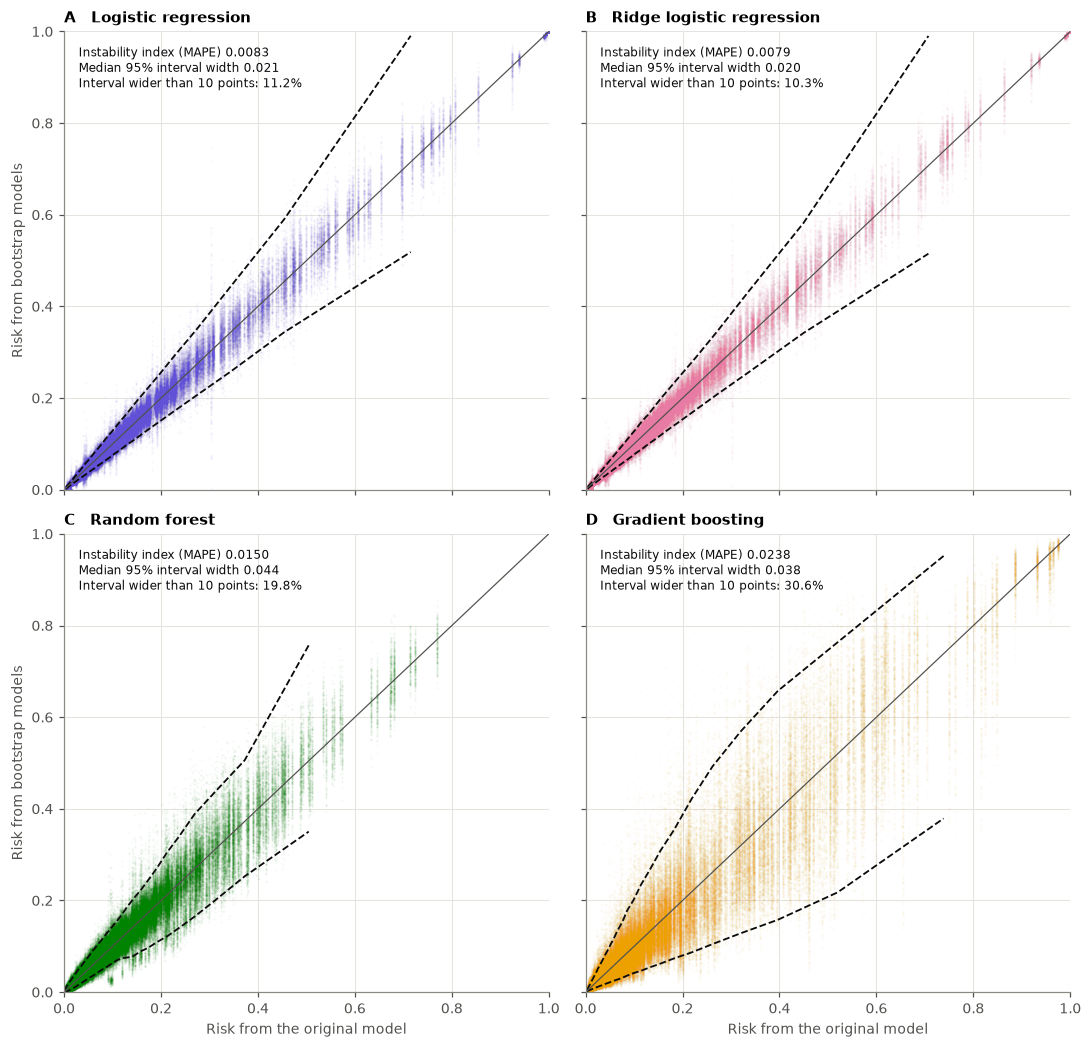

In [13]:
rng = np.random.default_rng(seed_for("plot-sample"))
SHOW = rng.choice(N_DEV, size=min(1500, N_DEV), replace=False)
AXMAX = float(min(1.0, math.ceil(max(np.quantile(FULL_RES[m].P, 0.998) for m in FULL_RES) * 10) / 10))


def envelope(p, P, n_bins=40):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    xs, lo, hi = [], [], []
    for k in range(len(edges) - 1):
        cols = np.flatnonzero(b == k)
        if cols.size < 5:
            continue
        vals = P[:, cols].astype(np.float64).ravel()
        xs.append(np.median(p[cols]))
        lo.append(np.quantile(vals, 0.025))
        hi.append(np.quantile(vals, 0.975))
    return np.array(xs), np.array(lo), np.array(hi)


fig, axes = plt.subplots(2, 2, figsize=(10, 9.6), sharex=True, sharey=True)
for ax, (m, res), letter in zip(axes.ravel(), FULL_RES.items(), "ABCD"):
    P, p = res.P, res.p_original
    x = np.repeat(p[SHOW], P.shape[0])
    yv = P[:, SHOW].T.ravel()
    ax.scatter(x, yv, s=1.5, alpha=0.05, color=MODEL_COLORS[m], lw=0, rasterized=True)
    xs, lo, hi = envelope(p, P)
    ax.plot(xs, lo, "--", color=INK, lw=1.2)
    ax.plot(xs, hi, "--", color=INK, lw=1.2)
    ax.plot([0, AXMAX], [0, AXMAX], color=INK2, lw=0.8)
    s = population_summary(FULL_SPREAD[m])
    ax.text(0.03, 0.97, f"Instability index (MAPE) {s['instability_index']:.4f}\n"
                        f"Median 95% interval width {s['width95_median']:.3f}\n"
                        f"Interval wider than 10 points: {100 * s['share_wide']:.1f}%",
            transform=ax.transAxes, va="top", fontsize=8, color=INK)
    ax.set_xlim(0, AXMAX)
    ax.set_ylim(0, AXMAX)
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
for ax in axes[1]:
    ax.set_xlabel("Risk from the original model")
for ax in axes[:, 0]:
    ax.set_ylabel("Risk from bootstrap models")
fig.tight_layout()
save_figure(fig, "p2_fig2_prediction_instability", "Prediction instability plots at the full development size, four model classes")

### Where instability lives (Figure P2-3)

**A.** Mean MAPE across bins of original risk. **B.** Classification instability index at the primary threshold: the share of bootstrap models whose decision differs from the original model's. **C.** Patients per 1,000 whose decision changes in more than 10% of refits, at each threshold.

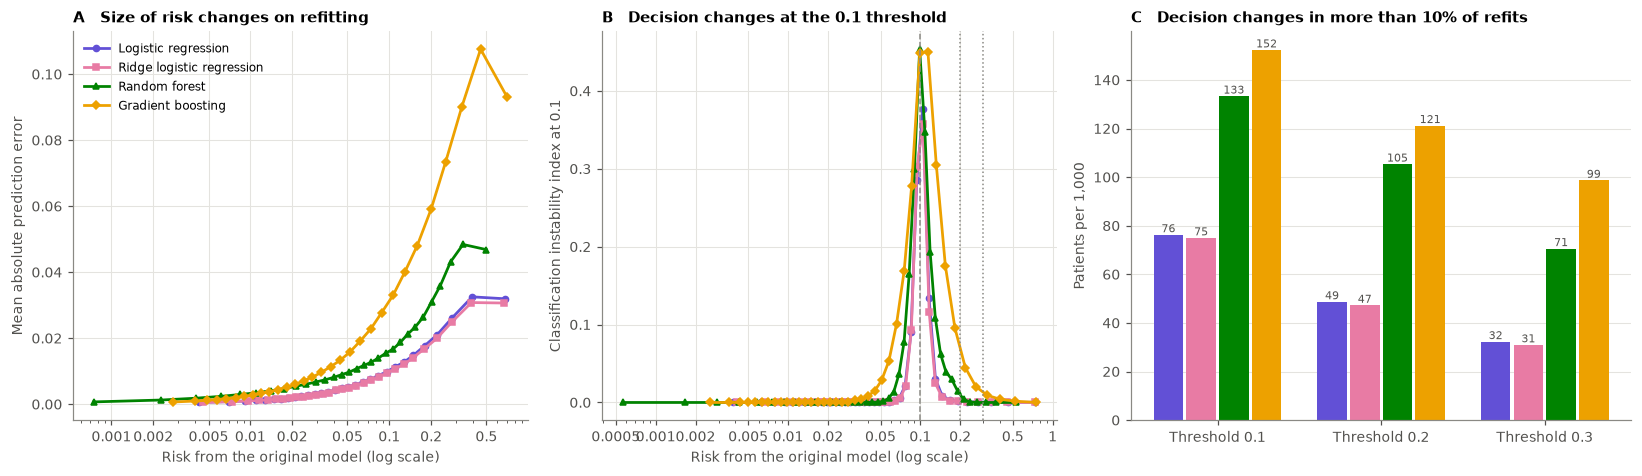

In [14]:
def binned(x, y, n_bins=30):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    cnt = np.bincount(b, minlength=len(edges) - 1)
    ok = cnt > 0
    xm = np.bincount(b, weights=x, minlength=len(edges) - 1)[ok] / cnt[ok]
    ym = np.bincount(b, weights=y, minlength=len(edges) - 1)[ok] / cnt[ok]
    return xm, ym


fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for m, res in FULL_RES.items():
    p = res.p_original
    xm, ym = binned(p, FULL_SPREAD[m]["mape"])
    axes[0].plot(xm, ym, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=4, lw=1.8, label=MODEL_LABELS[m])
    xm, ym = binned(p, FULL_SPREAD[m][f"cii@{T0:g}"], n_bins=40)
    axes[1].plot(xm, ym, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=4, lw=1.8)
for ax in axes[:2]:
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, fmt="{:g}")
    ax.set_xlabel("Risk from the original model (log scale)")
axes[0].set_ylabel("Mean absolute prediction error")
axes[0].set_title("Size of risk changes on refitting")
axes[0].legend(fontsize=8, loc="upper left")
for t in THRESHOLDS:
    axes[1].axvline(t, color=NEUTRAL, lw=1, ls=":" if t != T0 else "--")
axes[1].set_ylabel(f"Classification instability index at {T0:g}")
axes[1].set_title(f"Decision changes at the {T0:g} threshold")
panel_label(axes[0], "A")
panel_label(axes[1], "B")

ax = axes[2]
models = list(FULL_RES)
width = 0.8 / len(models)
for i, m in enumerate(models):
    vals = [1000 * float(np.mean(FULL_SPREAD[m][f"cii@{t:g}"] > CONFIG["unstable_share"])) for t in THRESHOLDS]
    xpos = np.arange(len(THRESHOLDS)) + (i - (len(models) - 1) / 2) * width
    bars = ax.bar(xpos, vals, width=width - 0.02, color=MODEL_COLORS[m], label=MODEL_LABELS[m])
    for xb, v in zip(xpos, vals):
        ax.text(xb, v, f"{v:.0f}", ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(np.arange(len(THRESHOLDS)))
ax.set_xticklabels([f"Threshold {t:g}" for t in THRESHOLDS])
ax.set_ylabel("Patients per 1,000")
ax.set_title("Decision changes in more than 10% of refits")
ax.grid(axis="x", visible=False)
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p2_fig3_where_instability_lives", "Instability by risk level and decision instability at three thresholds")

### Stable population metrics, unstable individuals (Figure P2-4)

**A.** AUROC of each of the 200 bootstrap models in the development sample (dots) and the original model (black bar). **B.** Cumulative distribution of the individual 95% uncertainty interval width (2.5th to 97.5th percentile of bootstrap risks). The contrast between the two panels is the central message: population-level performance can look settled while the risk given to an individual patient still depends on the sample.

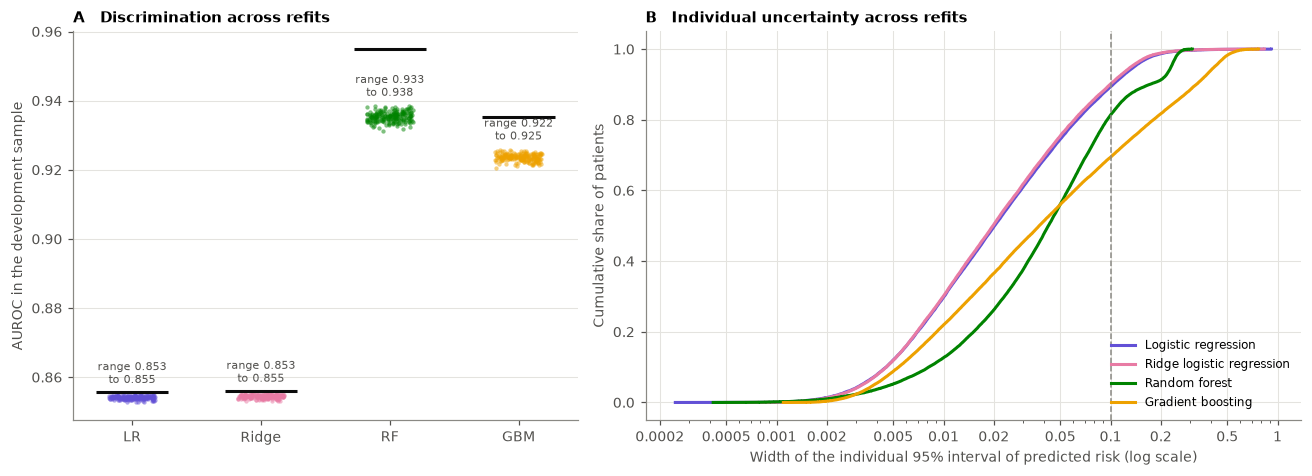

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
rng = np.random.default_rng(seed_for("jitter"))
for i, (m, res) in enumerate(FULL_RES.items()):
    rm = res.replicate_metrics
    auc = rm.loc[rm["sample"] == "bootstrap_test", "auroc"].to_numpy()
    ax.scatter(i + rng.uniform(-0.18, 0.18, auc.size), auc, s=8, alpha=0.5, color=MODEL_COLORS[m], lw=0)
    ax.hlines(res.performance_apparent["auroc"], i - 0.28, i + 0.28, color=INK, lw=2)
    ax.text(i, np.max(auc) + 0.002, f"range {np.quantile(auc, 0.025):.3f}\nto {np.quantile(auc, 0.975):.3f}",
            ha="center", va="bottom", fontsize=7, color=INK2)
ax.set_xticks(range(len(FULL_RES)))
ax.set_xticklabels([MODEL_SHORT[m] for m in FULL_RES])
ax.set_ylabel("AUROC in the development sample")
ax.set_title("Discrimination across refits")
ax.grid(axis="x", visible=False)
panel_label(ax, "A")

ax = axes[1]
for m, res in FULL_RES.items():
    w = np.sort(res.individual()["interval_width"].to_numpy())
    ax.step(w, np.arange(1, w.size + 1) / w.size, where="post", color=MODEL_COLORS[m], lw=2, label=MODEL_LABELS[m])
ax.axvline(CONFIG["wide_interval"], color=NEUTRAL, ls="--", lw=1)
ax.set_xscale("log")
plain_log_axis(ax.xaxis, fmt="{:g}")
ax.set_xlabel("Width of the individual 95% interval of predicted risk (log scale)")
ax.set_ylabel("Cumulative share of patients")
ax.set_title("Individual uncertainty across refits")
ax.legend(fontsize=8, loc="lower right")
panel_label(ax, "B")
fig.tight_layout()
save_figure(fig, "p2_fig4_population_vs_individual", "Bootstrap AUROC versus individual interval width")

### Calibration and decision-curve instability (Figures P2-S1 and P2-S2)

Both are evaluated in the development sample, as in the original audit. For random forests and boosting the development-sample calibration curve reflects partial memorisation of training patients rather than calibration in new patients; external calibration is assessed in notebook 3.

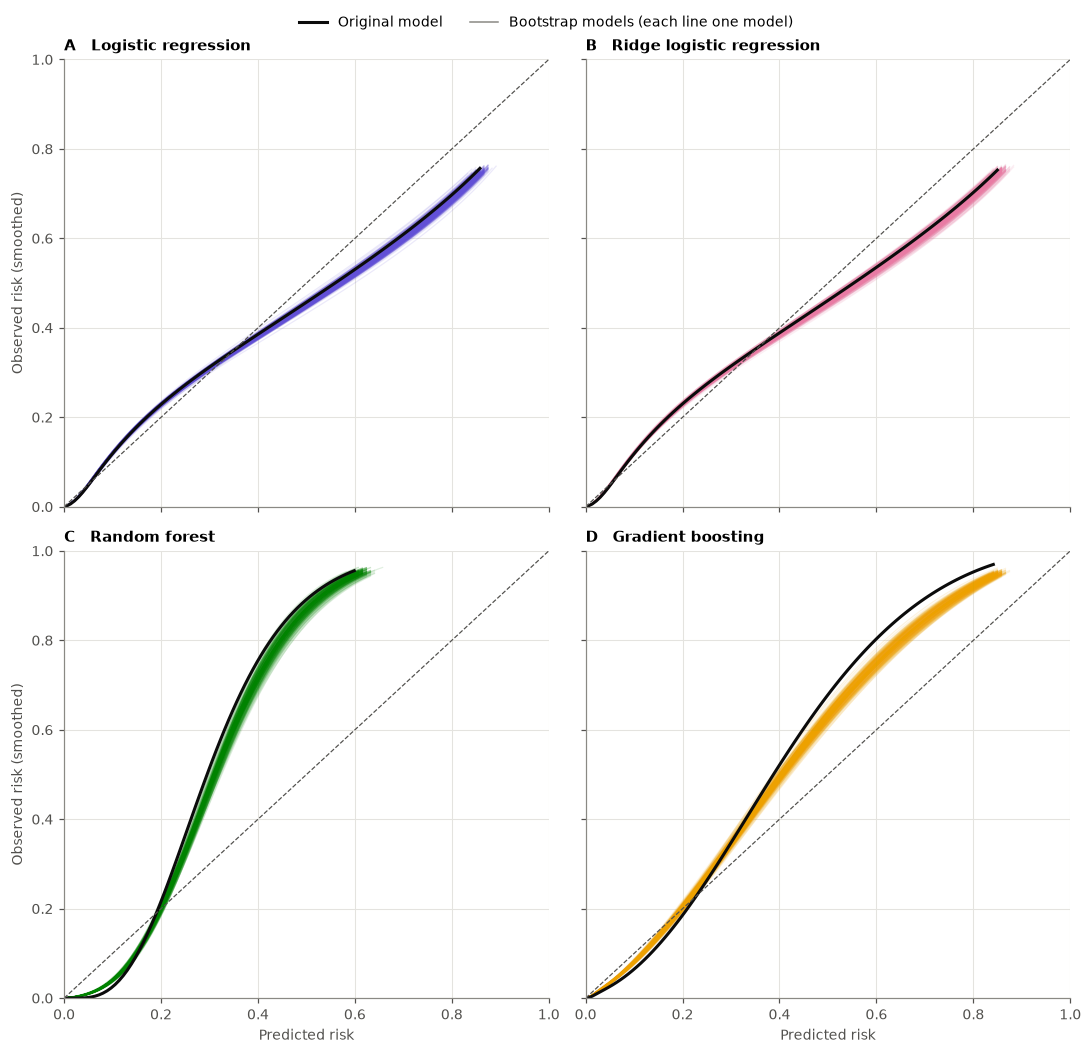

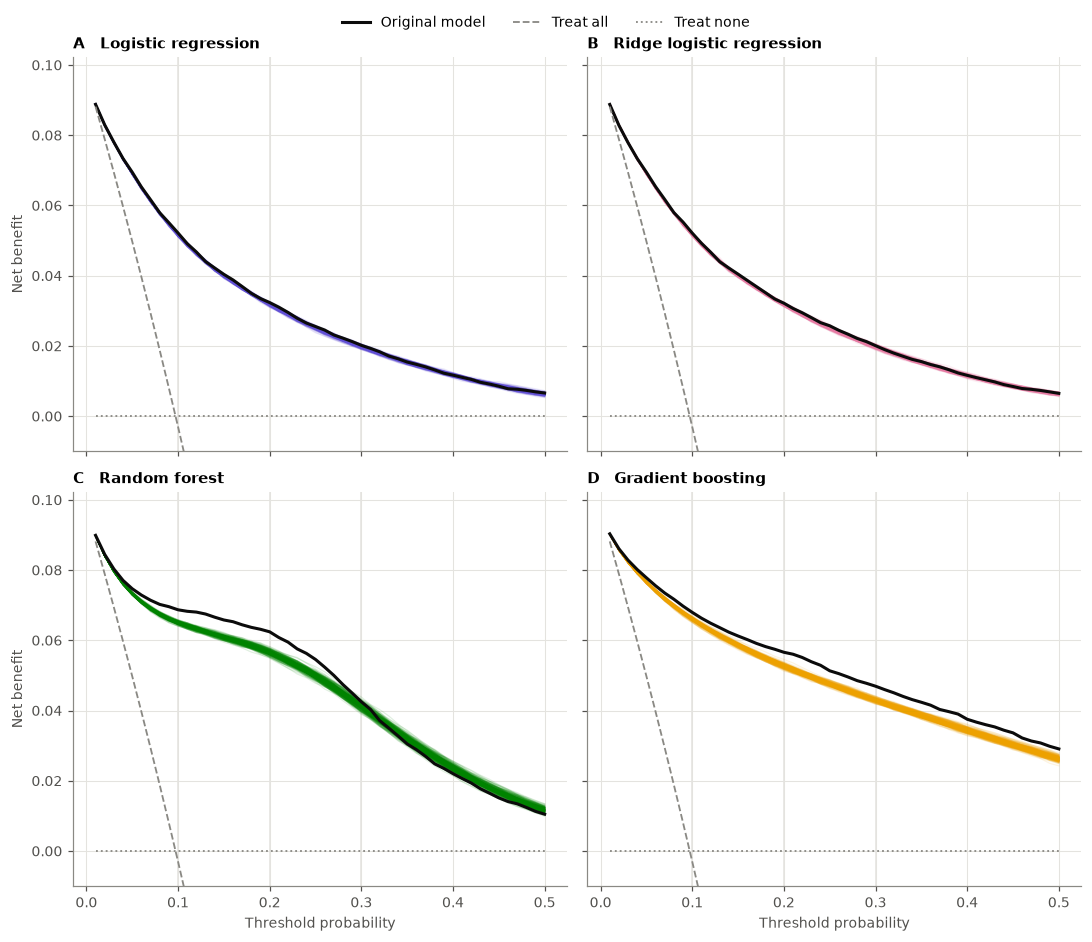

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9.4), sharex=True, sharey=True)
grid = np.linspace(0.005, AXMAX, 120)
for ax, (m, res), letter in zip(axes.ravel(), FULL_RES.items(), "ABCD"):
    ci = res.calibration_instability(grid=grid, method="spline")
    for curve in ci["replicates"]:
        ax.plot(ci["predicted"], curve, color=MODEL_COLORS[m], alpha=0.12, lw=0.8)
    ax.plot(ci["predicted"], ci["original"], color=INK, lw=2)
    ax.plot([0, AXMAX], [0, AXMAX], color=INK2, lw=0.8, ls="--")
    ax.set_xlim(0, AXMAX)
    ax.set_ylim(0, AXMAX)
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
for ax in axes[1]:
    ax.set_xlabel("Predicted risk")
for ax in axes[:, 0]:
    ax.set_ylabel("Observed risk (smoothed)")
fig.legend([Line2D([0], [0], color=INK, lw=2), Line2D([0], [0], color=NEUTRAL, lw=1)],
           ["Original model", "Bootstrap models (each line one model)"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
save_figure(fig, "p2_figS1_calibration_instability", "Calibration instability plots, bootstrap models in the development sample")

fig, axes = plt.subplots(2, 2, figsize=(10, 8.4), sharex=True, sharey=True)
ths = np.round(np.linspace(0.01, 0.5, 50), 3)
for ax, (m, res), letter in zip(axes.ravel(), FULL_RES.items(), "ABCD"):
    dc = res.decision_curve_instability(thresholds=ths)
    for _, g in dc[dc["strategy"] == "replicate"].groupby("replicate"):
        ax.plot(g["threshold"], g["net_benefit"], color=MODEL_COLORS[m], alpha=0.12, lw=0.8)
    for strat, style in (("original", dict(color=INK, lw=2)), ("treat_all", dict(color=NEUTRAL, lw=1.2, ls="--")),
                         ("treat_none", dict(color=NEUTRAL, lw=1.2, ls=":"))):
        g = dc[dc["strategy"] == strat]
        ax.plot(g["threshold"], g["net_benefit"], **style)
    for t in THRESHOLDS:
        ax.axvline(t, color=GRID, lw=1, zorder=0)
    ax.set_ylim(-0.01, PREV * 1.05)
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
for ax in axes[1]:
    ax.set_xlabel("Threshold probability")
for ax in axes[:, 0]:
    ax.set_ylabel("Net benefit")
fig.legend([Line2D([0], [0], color=INK, lw=2), Line2D([0], [0], color=NEUTRAL, lw=1.2, ls="--"),
            Line2D([0], [0], color=NEUTRAL, lw=1.2, ls=":")], ["Original model", "Treat all", "Treat none"],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
save_figure(fig, "p2_figS2_decision_curve_instability", "Decision-curve instability, bootstrap models in the development sample")

### Full model equations (logistic models)

TRIPOD+AI asks for the full model to be reported. Coefficients are on the standardised scale used inside the pipeline; medians, means and standard deviations needed to apply the model are saved with them.

In [17]:
def model_equation(m):
    fitted, _ = fit_quietly(MODELS[m], X_dev, y_dev, random_state=seed_for(m, "full") % (2**31 - 1))
    prep, est = fitted.named_steps["prep"], fitted.named_steps["model"]
    names = PRED + [f"missing: {GROUP_NAMES[GROUP_INDEX.index(g)]}" for g in prep.indicator_groups_]
    coef = np.ravel(est.coef_)
    intercept = float(np.ravel(est.intercept_)[0])
    medians = list(prep.medians_) + [np.nan] * len(prep.indicator_groups_)
    eq = pd.DataFrame({"term": names, "coefficient_standardised": coef, "odds_ratio_per_sd": np.exp(coef),
                       "centre": prep.mean_, "scale": prep.sd_, "imputation_median": medians})
    eq = pd.concat([pd.DataFrame([{"term": "(intercept)", "coefficient_standardised": intercept}]), eq], ignore_index=True)
    extra = {"chosen_C": float(np.ravel(est.C_)[0])} if hasattr(est, "C_") else {}
    return fitted, eq, extra


ORIGINAL_FITS = {}
for m in ("lr", "ridge"):
    if m in MODELS:
        fitted, eq, extra = model_equation(m)
        ORIGINAL_FITS[m] = fitted
        save_table(eq, f"tableS_p2_equation_{m}", f"Full model equation, {MODEL_LABELS[m]}")
        print(f"{MODEL_LABELS[m]}: {len(eq) - 1} terms {extra}")

Logistic regression: 75 terms {}
Ridge logistic regression: 75 terms {'chosen_C': 0.03162277660168379}


## 6. Who bears the instability? (Figure P2-5)

Instability rises with risk, so subgroups with higher mortality will look less stable for that reason alone. The **risk-standardised instability ratio** removes this: for each patient the expected MAPE is the average MAPE of all patients with a similar original risk (40 risk bins); the ratio is the subgroup's observed mean MAPE divided by its expected mean MAPE. A ratio above 1 means the subgroup's predictions are less stable than its risk level explains (for example because similar patients are rare in the data). 95% intervals: 300 patient-level bootstrap resamples within each subgroup.

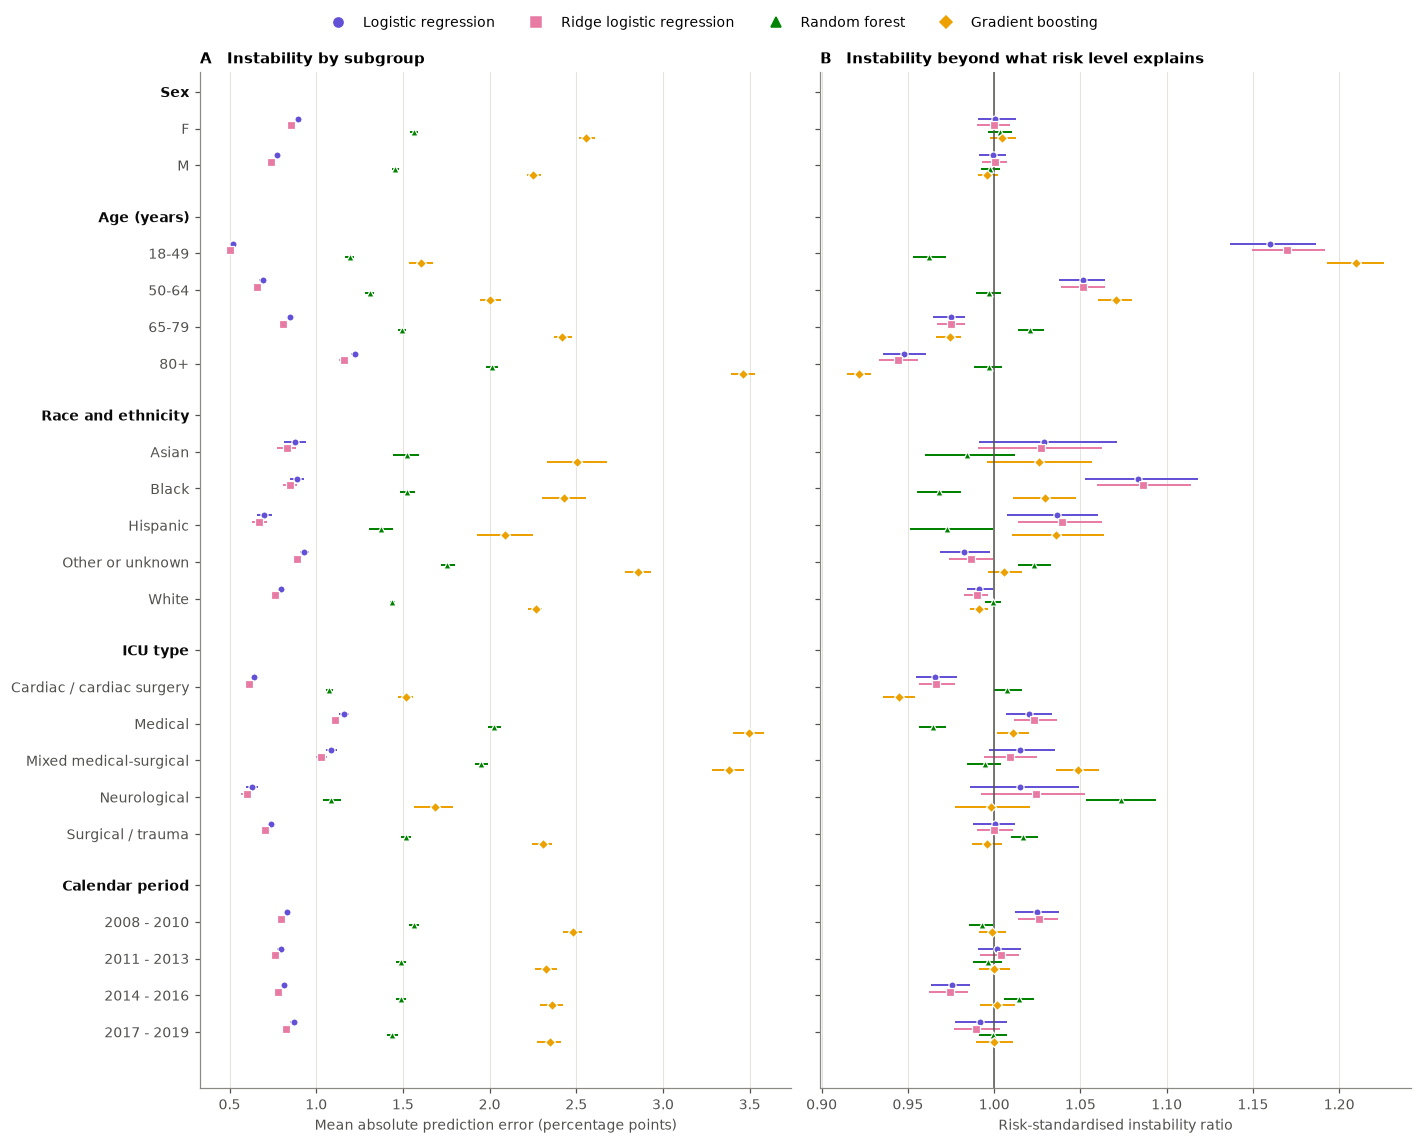

In [18]:
def risk_standardised(mape, risk, frame, extra=None, n_bins=40, n_boot=300, seed=0):
    """Observed / expected instability per subgroup; expected from the instability of patients with similar risk."""
    edges = np.unique(np.quantile(risk, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, risk, side="right") - 1, 0, len(edges) - 2)
    cnt = np.maximum(np.bincount(b, minlength=len(edges) - 1), 1)
    expected = (np.bincount(b, weights=mape, minlength=len(edges) - 1) / cnt)[b]
    rng = np.random.default_rng(seed)
    rows = []
    for dim, dim_label in SUBGROUP_DIMS.items():
        values = frame[dim].astype(str).to_numpy()
        for level in sorted(pd.unique(values)):
            if level in ("nan", "None", "<NA>"):
                continue
            idx = np.flatnonzero(values == level)
            if idx.size < 30:
                continue
            obs, exp_ = mape[idx], expected[idx]
            row = {"dimension": dim_label, "level": level, "n": int(idx.size), "mean_risk": float(risk[idx].mean()),
                   "mape": float(obs.mean()), "expected_mape": float(exp_.mean()), "ratio": float(obs.mean() / exp_.mean())}
            if n_boot:
                ratios, means = np.empty(n_boot), np.empty(n_boot)
                for k in range(n_boot):
                    r = rng.integers(0, idx.size, idx.size)
                    means[k] = obs[r].mean()
                    ratios[k] = means[k] / exp_[r].mean()
                row.update({"mape_lower": np.quantile(means, 0.025), "mape_upper": np.quantile(means, 0.975),
                            "ratio_lower": np.quantile(ratios, 0.025), "ratio_upper": np.quantile(ratios, 0.975)})
            for name, arr in (extra or {}).items():
                row[name] = float(np.mean(arr[idx]))
            rows.append(row)
    return pd.DataFrame(rows)


SUBGROUP_FULL = []
for m, res in FULL_RES.items():
    extra = {f"flip_prone_per_1000@{thr:g}": 1000.0 * (FULL_SPREAD[m][f"cii@{thr:g}"] > CONFIG["unstable_share"])
             for thr in THRESHOLDS}
    t = risk_standardised(FULL_SPREAD[m]["mape"], res.p_original, dev, extra=extra, seed=seed_for(m, "subgroup"))
    SUBGROUP_FULL.append(t.assign(model=MODEL_LABELS[m], model_key=m))
SUBGROUP_FULL = pd.concat(SUBGROUP_FULL, ignore_index=True)
save_table(SUBGROUP_FULL.drop(columns="model_key").round(5), "table4_subgroup_instability_full",
           "Subgroup instability at the full development size: MAPE, risk-standardised ratio, decision changes")


def subgroup_dotplot(table, value, lower, upper, ax, log=False, ref=None, xlabel=""):
    first = table[table["model_key"] == table["model_key"].iloc[0]]
    labels, ypos, y, headers = [], {}, 0, []
    for dim in first["dimension"].unique():
        headers.append((y, dim))
        y += 1
        for lv in first.loc[first["dimension"] == dim, "level"]:
            ypos[(dim, lv)] = y
            labels.append((y, lv))
            y += 1
        y += 0.4
    models = list(table["model_key"].unique())
    off = np.linspace(-0.27, 0.27, len(models))
    for o, m in zip(off, models):
        sub = table[table["model_key"] == m]
        yy = np.array([ypos[(d, l)] for d, l in zip(sub["dimension"], sub["level"])]) + o
        ax.hlines(yy, sub[lower], sub[upper], color=MODEL_COLORS[m], lw=1.3)
        ax.scatter(sub[value], yy, s=22, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], zorder=3,
                   edgecolors="white", linewidths=0.8)
    if ref is not None:
        ax.axvline(ref, color=INK2, lw=1)
    lo_, hi_ = float(table[lower].min()), float(table[upper].max())
    if log and hi_ / max(lo_, 1e-9) >= 1.6:
        ax.set_xscale("log")
        ticks = [t for t in (0.25, 0.33, 0.5, 0.67, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0) if lo_ * 0.9 <= t <= hi_ * 1.1]
        ax.xaxis.set_major_locator(matplotlib.ticker.FixedLocator(ticks))
        ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    elif log:
        xlabel = xlabel.replace(" (log scale)", "")
    ax.set_yticks([p for p, _ in labels] + [p for p, _ in headers])
    ax.set_yticklabels([l for _, l in labels] + [h for _, h in headers])
    for tick, (p, _) in zip(ax.get_yticklabels()[len(labels):], headers):
        tick.set_fontweight("bold")
        tick.set_color(INK)
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)


plot_tab = SUBGROUP_FULL.copy()
for c in ("mape", "mape_lower", "mape_upper"):
    plot_tab[c] = 100 * plot_tab[c]
n_rows = plot_tab[plot_tab["model_key"] == plot_tab["model_key"].iloc[0]].shape[0] + plot_tab["dimension"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.34 * n_rows + 1.6), sharey=True)
subgroup_dotplot(plot_tab, "mape", "mape_lower", "mape_upper", axes[0], xlabel="Mean absolute prediction error (percentage points)")
axes[0].set_title("Instability by subgroup")
panel_label(axes[0], "A")
subgroup_dotplot(plot_tab, "ratio", "ratio_lower", "ratio_upper", axes[1], log=True, ref=1.0,
                 xlabel="Risk-standardised instability ratio (log scale)")
axes[1].set_title("Instability beyond what risk level explains")
panel_label(axes[1], "B")
fig.legend(handles=model_handles(FULL_RES, line=False), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save_figure(fig, "p2_fig5_subgroup_instability", "Instability by subgroup and risk-standardised instability ratio, full development size")

## 7. The multiverse experiment: what instability really is, and how well it is measured

Riley and Collins define instability as the variation in an individual's predicted risk across models developed on *different samples of the same size from the same population*. In practice only one sample exists, so the bootstrap stands in for the others. Here the others exist: MIMIC-IV is large enough to draw many independent development samples, so the quantity the bootstrap tries to estimate can be observed directly for patients who were never used for development.

### 7.1 Audit panel, development pool and sample sizes

The minimum sample size from the three analytic criteria (shrinkage, optimism in R-squared, precise overall risk) is computed for the observed mortality, the optimism-corrected C statistic of the logistic model, and the candidate parameter count of that model (predictors plus missingness indicators), and is added to the pre-specified sizes.

In [19]:
rng = np.random.default_rng(seed_for("audit-split"))
n_audit = min(CONFIG["audit_max"], int(CONFIG["audit_fraction"] * N_DEV))
audit_parts = []
for value in (0, 1):
    rows_v = np.flatnonzero(y_dev == value)
    audit_parts.append(rng.choice(rows_v, size=int(round(n_audit * rows_v.size / N_DEV)), replace=False))
AUDIT = np.sort(np.concatenate(audit_parts))
POOL = np.setdiff1d(np.arange(N_DEV), AUDIT)
PANEL = np.sort(np.random.default_rng(seed_for("ext-panel")).choice(len(y_ext), size=min(CONFIG["ext_panel"], len(y_ext)), replace=False))
X_aud, y_aud, aud_frame = X_dev[AUDIT], y_dev[AUDIT], dev.iloc[AUDIT].reset_index(drop=True)
X_pan = X_ext[PANEL]

c_lr = float(TABLE2.loc[(TABLE2["model"] == MODEL_LABELS["lr"]) & (TABLE2["metric"] == "AUROC"), "optimism_corrected"].iloc[0])
P_PARAMS = len(PRED) + len(ORIGINAL_FITS["lr"].named_steps["prep"].indicator_groups_)
R2_CS = cox_snell_r2_from_c(c_lr, PREV, n_sim=400_000, random_state=seed_for("r2"))
SS = minimum_sample_size_binary(P_PARAMS, PREV, r2_cox_snell=R2_CS)
N_RILEY = int(SS.minimum_n)
LIMIT = int(CONFIG["fpc_max_fraction"] * POOL.size)
SIZES = sorted({s for s in CONFIG["base_sizes"] + [N_RILEY] if 50 <= s <= LIMIT})
RILEY_IN = N_RILEY in SIZES


def size_label(n):
    return f"{n:,}*" if n == N_RILEY else f"{n:,}"


print(f"Audit panel: {AUDIT.size:,} patients ({y_aud.sum():,} deaths); development pool: {POOL.size:,}; "
      f"eICU-CRD panel for notebook 3: {PANEL.size:,}")
print(f"Analytic minimum sample size: {N_RILEY:,} (C = {c_lr:.3f}, Cox-Snell R2 = {R2_CS:.4f}, "
      f"{P_PARAMS} candidate parameters, {N_RILEY * PREV:.0f} events)")
display(SS.criteria)
print("Development sizes:", ", ".join(size_label(n) for n in SIZES), "(* = analytic minimum)")
if not RILEY_IN:
    print(f"Note: the analytic minimum {N_RILEY:,} exceeds {CONFIG['fpc_max_fraction']:.0%} of the pool and is not evaluated.")

MV_DESIGN = {"audit_stay_ids": dev["stay_id"].iloc[AUDIT].astype(int).tolist(),
             "pool_size": int(POOL.size), "panel_stay_ids": ext["stay_id"].iloc[PANEL].astype(int).tolist(),
             "sizes": SIZES, "n_riley": N_RILEY, "riley_c": c_lr, "riley_r2_cs": R2_CS, "riley_parameters": P_PARAMS,
             "riley_criteria": SS.criteria.to_dict(orient="records"),
             "k_truth": CONFIG["k_truth"], "r_boot": CONFIG["r_boot"], "b_curve": CONFIG["b_curve"]}
save_json(MV_DESIGN, f"multiverse_design_{PRESET_KEY}", "Audit panel, eICU-CRD panel and sizes of the multiverse experiment")

Audit panel: 7,993 patients (778 deaths); development pool: 31,973; eICU-CRD panel for notebook 3: 20,000
Analytic minimum sample size: 3,906 (C = 0.853, Cox-Snell R2 = 0.1573, 75 candidate parameters, 380 events)


,criterion,sample_size,events,events_per_parameter,shrinkage,shrinkage_at_minimum
0,criterion 1: shrinkage,3906,379.986188,5.066483,0.900000,0.9
1,criterion 2: optimism in R-squared,2883,280.465996,3.739547,0.869583,0.9
2,criterion 3: overall risk precision,135,13.133163,0.175109,NaN,0.9


Development sizes: 500, 1,000, 2,000, 3,906*, 4,000, 8,000, 16,000 (* = analytic minimum)


WindowsPath('C:/Users/kruta/Downloads/outputs/part2/data/multiverse_design_01fb9742.json')

### 7.2 Study design (Figure P2-1)

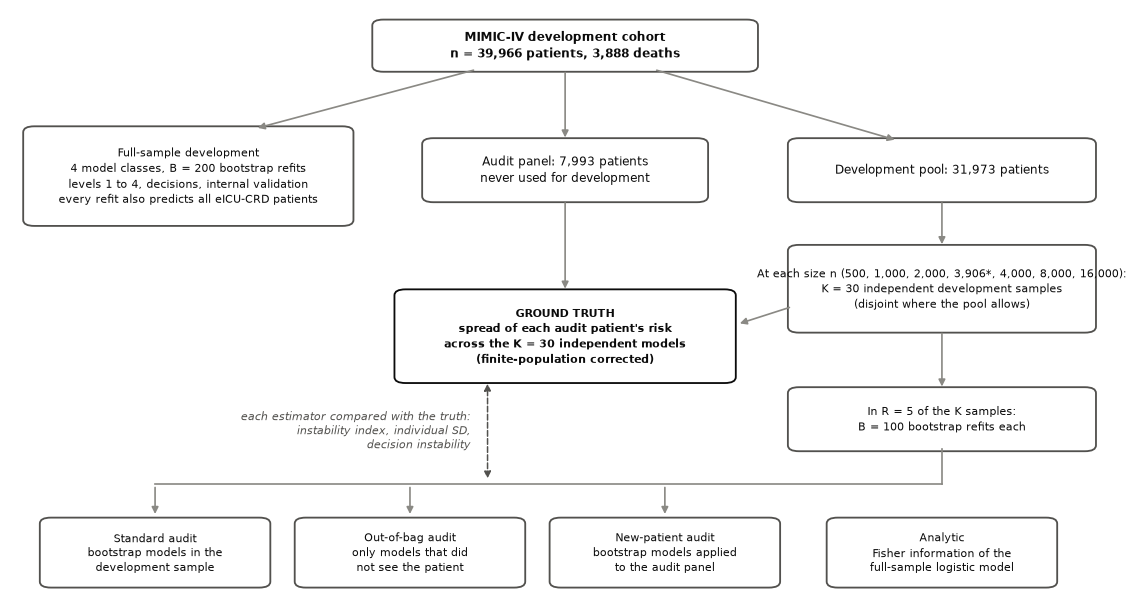

In [20]:
def box(ax, x, y, w, h, text, edge=INK2, face="white", size=8, weight="normal"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.004,rounding_size=0.01",
                                lw=1.2, edgecolor=edge, facecolor=face))
    ax.text(x, y, text, ha="center", va="center", fontsize=size, color=INK, linespacing=1.35, fontweight=weight)


def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=NEUTRAL, lw=1.1))


K, R, B = CONFIG["k_truth"], CONFIG["r_boot"], CONFIG["b_curve"]
fig, ax = plt.subplots(figsize=(13, 7.0))
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
box(ax, 0.5, 0.94, 0.34, 0.08, f"MIMIC-IV development cohort\nn = {N_DEV:,} patients, {int(y_dev.sum()):,} deaths", weight="bold")
box(ax, 0.16, 0.72, 0.29, 0.16, f"Full-sample development\n4 model classes, B = {CONFIG['b_full']} bootstrap refits\n"
                               "levels 1 to 4, decisions, internal validation\nevery refit also predicts all eICU-CRD patients", size=7.5)
box(ax, 0.5, 0.73, 0.25, 0.10, f"Audit panel: {AUDIT.size:,} patients\nnever used for development")
box(ax, 0.84, 0.73, 0.27, 0.10, f"Development pool: {POOL.size:,} patients")
arrow(ax, 0.42, 0.90, 0.22, 0.80)
arrow(ax, 0.5, 0.90, 0.5, 0.78)
arrow(ax, 0.58, 0.90, 0.80, 0.78)
box(ax, 0.84, 0.53, 0.27, 0.14, f"At each size n ({', '.join(size_label(n) for n in SIZES)}):\n"
                               f"K = {K} independent development samples\n(disjoint where the pool allows)", size=7.5)
arrow(ax, 0.84, 0.68, 0.84, 0.60)
box(ax, 0.5, 0.45, 0.30, 0.15, "GROUND TRUTH\nspread of each audit patient's risk\n"
                              f"across the K = {K} independent models\n(finite-population corrected)", edge=INK, weight="bold", size=7.5)
arrow(ax, 0.705, 0.50, 0.655, 0.47)
arrow(ax, 0.5, 0.68, 0.5, 0.525)
box(ax, 0.84, 0.31, 0.27, 0.10, f"In R = {R} of the K samples:\nB = {B} bootstrap refits each", size=7.5)
arrow(ax, 0.84, 0.46, 0.84, 0.36)
ax.plot([0.84, 0.84], [0.26, 0.20], color=NEUTRAL, lw=1.1)
ax.plot([0.13, 0.84], [0.20, 0.20], color=NEUTRAL, lw=1.1)
ests = [("Standard audit\nbootstrap models in the\ndevelopment sample", 0.13), ("Out-of-bag audit\nonly models that did\nnot see the patient", 0.36),
        ("New-patient audit\nbootstrap models applied\nto the audit panel", 0.59)]
for text, x in ests:
    arrow(ax, x, 0.20, x, 0.145)
    box(ax, x, 0.085, 0.2, 0.11, text, size=7.2)
box(ax, 0.84, 0.085, 0.2, 0.11, "Analytic\nFisher information of the\nfull-sample logistic model", size=7.2)
ax.annotate("", xy=(0.43, 0.375), xytext=(0.43, 0.205),
            arrowprops=dict(arrowstyle="<|-|>", color=INK2, lw=1, ls="--"))
ax.text(0.415, 0.29, "each estimator compared with the truth:\ninstability index, individual SD,\ndecision instability",
        ha="right", va="center", fontsize=7.5, color=INK2, style="italic")
save_figure(fig, "p2_fig1_design", "Design of the full-sample audit and the multiverse experiment")

### 7.3 Running the experiment

Each independent sample is drawn once per size and **shared by all model classes** (paired design). Every model fitted on an independent sample predicts the audit panel and the eICU-CRD panel; the first R samples also receive B bootstrap refits. Work is split into parallel tasks and each finished (model, size) block is cached, so the cell can be interrupted and re-run.

In [21]:
def run_parallel(tasks):
    with parallel_config(backend="loky", inner_max_num_threads=1):
        return Parallel(n_jobs=N_JOBS, verbose=0)(tasks)


def truth_task(builder, idx, seed, want_dev, X, y, Xa, Xp):
    t0 = time.perf_counter()
    model, n_conv = fit_quietly(builder, X[idx], y[idx], random_state=seed % (2**31 - 1))
    return {"p_aud": builder.predict_risk(model, Xa).astype(np.float32),
            "p_pan": builder.predict_risk(model, Xp).astype(np.float32),
            "p_dev": builder.predict_risk(model, X[idx]).astype(np.float32) if want_dev else None,
            "n_conv": n_conv, "seconds": time.perf_counter() - t0}


def boot_task(builder, dev_idx, seeds, X, y, Xa, Xp):
    Xd, yd = X[dev_idx], y[dev_idx]
    n = dev_idx.size
    out = {"P_dev": np.empty((len(seeds), n), np.float32), "P_aud": np.empty((len(seeds), Xa.shape[0]), np.float32),
           "P_pan": np.empty((len(seeds), Xp.shape[0]), np.float32), "inbag": np.zeros((len(seeds), n), bool)}
    for j, s in enumerate(seeds):
        rng = np.random.default_rng(s)
        for _ in range(50):
            b = rng.integers(0, n, n)
            if 0 < yd[b].sum() < n:
                break
        model, _ = fit_quietly(builder, Xd[b], yd[b], random_state=s % (2**31 - 1))
        out["P_dev"][j] = builder.predict_risk(model, Xd)
        out["P_aud"][j] = builder.predict_risk(model, Xa)
        out["P_pan"][j] = builder.predict_risk(model, Xp)
        out["inbag"][j, b] = True
    return out


def dev_samples(n):
    rng = np.random.default_rng(seed_for("samples", n))
    K = CONFIG["k_truth"]
    if K * n <= POOL.size:
        perm = rng.permutation(POOL)
        samples, scheme, f = [np.sort(perm[k * n:(k + 1) * n]) for k in range(K)], "disjoint", 0.0
    else:
        samples, scheme, f = [np.sort(rng.choice(POOL, size=n, replace=False)) for _ in range(K)], "overlapping", n / POOL.size
    for s in samples:
        assert 0 < y_dev[s].sum() < n, "a development sample contains a single outcome class"
    return samples, scheme, f


# Exemplar audit patients, chosen before the experiment from the full-sample logistic model.
risk_full_aud = FULL_RES["lr"].p_original[AUDIT]
EXEMPLAR_TARGETS = [0.02, 0.05, 0.10, 0.15, 0.25, 0.45]
EXEMPLARS = []
for target in EXEMPLAR_TARGETS:
    order = np.argsort(np.abs(risk_full_aud - target))
    EXEMPLARS.append(int(next(i for i in order if i not in EXEMPLARS)))


def flat(prefix, d):
    return {f"{prefix}__{k}": np.asarray(v) for k, v in d.items()}


def unflat(npz, prefix):
    return {k.split("__", 1)[1]: npz[k] for k in npz.files if k.startswith(prefix + "__")}


def run_size(m, n):
    builder = MODELS[m]
    tpath = CACHE / f"truth_{m}_{n}.npz"
    if CONFIG["force"] or not tpath.exists():
        samples, scheme, f = dev_samples(n)
        res = run_parallel([delayed(truth_task)(builder, samples[k], seed_for(m, n, "truth", k), k < CONFIG["r_boot"],
                                                X_dev, y_dev, X_aud, X_pan) for k in range(CONFIG["k_truth"])])
        extra = {f"p_dev_{k}": res[k]["p_dev"] for k in range(CONFIG["r_boot"])}
        np.savez_compressed(tpath, T_aud=np.vstack([r["p_aud"] for r in res]), T_pan=np.vstack([r["p_pan"] for r in res]),
                            samples=np.vstack(samples).astype(np.int32), scheme=scheme, f=f,
                            n_conv=np.array([r["n_conv"] for r in res]), seconds=np.array([r["seconds"] for r in res]), **extra)
    truth = np.load(tpath)
    missing = [r for r in range(CONFIG["r_boot"]) if CONFIG["force"] or not (CACHE / f"boot_{m}_{n}_{r}.npz").exists()]
    if missing:
        chunk = CONFIG["chunk"]
        jobs, keys = [], []
        for r in missing:
            seeds = [seed_for(m, n, "boot", r, b) for b in range(CONFIG["b_curve"])]
            for c0 in range(0, len(seeds), chunk):
                jobs.append(delayed(boot_task)(builder, truth["samples"][r], seeds[c0:c0 + chunk], X_dev, y_dev, X_aud, X_pan))
                keys.append(r)
        outs = run_parallel(jobs)
        for r in missing:
            parts = [o for o, k in zip(outs, keys) if k == r]
            P_dev = np.vstack([p["P_dev"] for p in parts])
            P_aud = np.vstack([p["P_aud"] for p in parts])
            P_pan = np.vstack([p["P_pan"] for p in parts])
            inbag = np.vstack([p["inbag"] for p in parts])
            ref_dev, ref_aud, ref_pan = truth[f"p_dev_{r}"], truth["T_aud"][r], truth["T_pan"][r]
            summaries = {**flat("dev", spread_summary(P_dev, ref_dev)), **flat("oob", spread_summary(P_dev, ref_dev, use=~inbag)),
                         **flat("new", spread_summary(P_aud, ref_aud)), **flat("pan", spread_summary(P_pan, ref_pan))}
            np.savez_compressed(CACHE / f"boot_{m}_{n}_{r}.npz", exemplars=P_aud[:, EXEMPLARS], **summaries)
    return truth


MV_TIMES = []
for m in CONFIG["models"]:
    for n in SIZES:
        t0 = time.perf_counter()
        run_size(m, n)
        MV_TIMES.append({"model": m, "n": n, "seconds": time.perf_counter() - t0})
        print(f"   {MODEL_LABELS[m]:<27} n = {n:>6,}: {MV_TIMES[-1]['seconds'] / 60:5.1f} min", flush=True)
PROV.step("Multiverse experiment", sum(t["seconds"] for t in MV_TIMES))

   Logistic regression         n =    500:   0.0 min
   Logistic regression         n =  1,000:   0.0 min
   Logistic regression         n =  2,000:   0.0 min
   Logistic regression         n =  3,906:   0.0 min
   Logistic regression         n =  4,000:   0.0 min
   Logistic regression         n =  8,000:   0.0 min
   Logistic regression         n = 16,000:   0.8 min
   Ridge logistic regression   n =    500:   0.0 min
   Ridge logistic regression   n =  1,000:   0.0 min
   Ridge logistic regression   n =  2,000:   0.0 min
   Ridge logistic regression   n =  3,906:   0.0 min
   Ridge logistic regression   n =  4,000:   0.0 min
   Ridge logistic regression   n =  8,000:   0.0 min
   Ridge logistic regression   n = 16,000:   4.8 min
   Random forest               n =    500:   0.0 min
   Random forest               n =  1,000:   0.0 min
   Random forest               n =  2,000:   0.0 min
   Random forest               n =  3,906:   0.0 min
   Random forest               n =  4,000:   0

### 7.4 Ground truth, estimators and the finite-population correction

Truth for patient *i* at size *n*: the standard deviation of the K independent-sample predictions, multiplied by 1/sqrt(1 - n/N_pool) when samples overlap (the variance of an estimator computed on a subsample without replacement shrinks by about that factor). MAPE is measured around the mean of the K predictions (scaled by sqrt(K/(K-1))). Decision instability uses a normal approximation on the logit scale with the corrected SD. The correction is checked against truly disjoint samples at the two largest sizes the pool allows.

In [22]:
def truth_summary(T, f):
    K = T.shape[0]
    s = spread_summary(T)
    c = 1.0 / math.sqrt(1.0 - f)
    s["sd"] = s["sd"] * c
    s["logit_sd"] = s["logit_sd"] * c
    s["mape"] = np.mean(np.abs(T.astype(np.float64) - s["mean"][None, :]), axis=0) * math.sqrt(K / (K - 1)) * c
    return add_logit_normal(s)


# Analytic (Fisher information) variance for the unpenalised logistic model: Var(logit p_i) = x_i' I^-1 x_i / n
lr_full = ORIGINAL_FITS["lr"]
prep_full = lr_full.named_steps["prep"]
Z1 = np.column_stack([np.ones(N_DEV), prep_full.transform(X_dev)])
w_full = lr_full.predict_proba(X_dev)[:, 1]
I_unit = (Z1 * (w_full * (1 - w_full))[:, None]).T @ Z1 / N_DEV
I_inv = np.linalg.pinv(I_unit)
Za = np.column_stack([np.ones(AUDIT.size), prep_full.transform(X_aud)])
V_UNIT = np.einsum("ij,jk,ik->i", Za, I_inv, Za)
L_AUD = logit(lr_full.predict_proba(X_aud)[:, 1])
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(40)
GH_W = GH_W / GH_W.sum()


def analytic_summary(n):
    s = np.sqrt(V_UNIT / n)
    Pq = expit(L_AUD[:, None] + s[:, None] * GH_X[None, :])
    mean = Pq @ GH_W
    out = {"mean": mean, "sd": np.sqrt(((Pq - mean[:, None]) ** 2) @ GH_W), "mape": np.abs(Pq - mean[:, None]) @ GH_W,
           "logit_mean": L_AUD, "logit_sd": s}
    out = add_logit_normal(out)
    for t in THRESHOLDS:
        out[f"minority_emp@{t:g}"] = out[f"minority@{t:g}"]
    return out


TRUTH, BOOT, PERF_ROWS, POP_ROWS = {}, {}, [], []
for m in CONFIG["models"]:
    for n in SIZES:
        tz = np.load(CACHE / f"truth_{m}_{n}.npz")
        f = float(tz["f"])
        TRUTH[(m, n)] = {"s": truth_summary(tz["T_aud"], f), "T_aud": tz["T_aud"], "f": f, "scheme": str(tz["scheme"]),
                         "n_conv": int(tz["n_conv"].sum())}
        POP_ROWS.append({"model": m, "n": n, "estimator": "truth", "replicate": -1, "f": f, "scheme": str(tz["scheme"]),
                         **population_summary(TRUTH[(m, n)]["s"])})
        for k, p in enumerate(tz["T_aud"]):
            p = p.astype(np.float64)
            PERF_ROWS.append({"model": m, "n": n, "k": k, "auroc": roc_auc(y_aud, p), "brier": brier_score(y_aud, p),
                              "mean_risk": p.mean(), **calibration_intercept_slope(y_aud, np.clip(p, EPS, 1 - EPS))})
        for r in range(CONFIG["r_boot"]):
            bz = np.load(CACHE / f"boot_{m}_{n}_{r}.npz")
            BOOT[(m, n, r)] = {e: unflat(bz, e) for e in ("dev", "oob", "new", "pan")} | {"exemplars": bz["exemplars"]}
            for e, label in (("dev", "bootstrap_standard"), ("oob", "bootstrap_oob"), ("new", "bootstrap_new_patients")):
                POP_ROWS.append({"model": m, "n": n, "estimator": label, "replicate": r, **population_summary(BOOT[(m, n, r)][e])})
        if m == "lr":
            POP_ROWS.append({"model": m, "n": n, "estimator": "analytic", "replicate": -1, **population_summary(analytic_summary(n))})
POP = pd.DataFrame(POP_ROWS)
MV_PERF = pd.DataFrame(PERF_ROWS)
save_table(POP.round(6), "table5_multiverse_population_summary",
           "Population-level instability by model, size and estimator (truth, bootstrap variants, analytic)")
save_table(MV_PERF.round(5), "tableS_p2_multiverse_performance", "Audit-panel performance of every independently developed model")

# Finite-population correction check against disjoint samples
fpc_rows = []
for n in [s for s in SIZES if s * 2 <= POOL.size and dev_samples(s)[1] == "overlapping"][-2:]:
    k_dis = min(4, POOL.size // n)
    perm = np.random.default_rng(seed_for("disjoint-check", n)).permutation(POOL)
    for m in CONFIG["models"]:
        cpath = CACHE / f"fpccheck_{m}_{n}.npz"
        if CONFIG["force"] or not cpath.exists():
            res = run_parallel([delayed(truth_task)(MODELS[m], np.sort(perm[k * n:(k + 1) * n]), seed_for(m, n, "dis", k), False,
                                                    X_dev, y_dev, X_aud, X_pan[:10]) for k in range(k_dis)])
            np.savez_compressed(cpath, T=np.vstack([r["p_aud"] for r in res]))
        Td = np.load(cpath)["T"].astype(np.float64)
        rms_dis = math.sqrt(np.mean(np.var(Td, axis=0, ddof=1)))
        rms_fpc = math.sqrt(np.mean(TRUTH[(m, n)]["s"]["sd"] ** 2))
        fpc_rows.append({"model": MODEL_LABELS[m], "n": n, "pool_fraction": n / POOL.size, "disjoint_samples": k_dis,
                         "rms_sd_disjoint": rms_dis, "rms_sd_overlapping_corrected": rms_fpc, "ratio": rms_fpc / rms_dis})
FPC_CHECK = pd.DataFrame(fpc_rows)
if len(FPC_CHECK):
    save_table(FPC_CHECK.round(5), "tableS_p2_fpc_check", "Finite-population correction checked against disjoint development samples")
    display(FPC_CHECK.round(4))

,model,n,pool_fraction,disjoint_samples,rms_sd_disjoint,rms_sd_overlapping_corrected,ratio
0,Logistic regression,4000,0.1251,4,0.0541,0.0520,0.9617
1,Ridge logistic regression,4000,0.1251,4,0.0391,0.0388,0.9933
2,Random forest,4000,0.1251,4,0.0214,0.0228,1.0656
3,Gradient boosting,4000,0.1251,4,0.0766,0.0783,1.0225
4,Logistic regression,8000,0.2502,3,0.0399,0.0385,0.9654
5,Ridge logistic regression,8000,0.2502,3,0.0331,0.0308,0.9302
6,Random forest,8000,0.2502,3,0.0207,0.0209,1.0093
7,Gradient boosting,8000,0.2502,3,0.0625,0.0682,1.0914


### 7.5 How instability falls with sample size (Figure P2-6)

**A.** True instability index (MAPE) on the audit panel; the grey dashed line is the analytic Fisher-information prediction for the logistic model. **B.** Share of patients whose decision at the primary threshold is unstable (more than 10% of independently developed models disagree with the majority). **C.** AUROC of the K independently developed models on the same audit panel (median and 95% range). The vertical line marks the analytic minimum sample size.

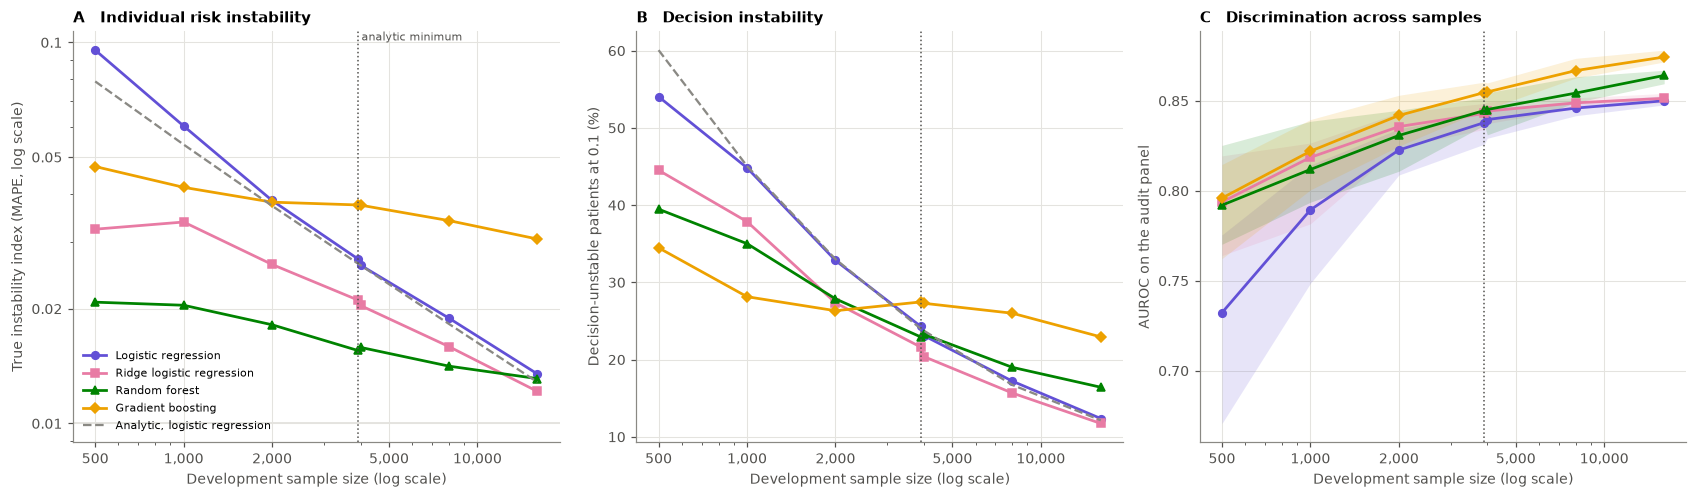

In [23]:
agg_truth = POP[POP["estimator"] == "truth"]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
for m in CONFIG["models"]:
    t = agg_truth[agg_truth["model"] == m].sort_values("n")
    kw = dict(color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=5, lw=1.8)
    axes[0].plot(t["n"], t["instability_index"], label=MODEL_LABELS[m], **kw)
    axes[1].plot(t["n"], 100 * t[f"share_unstable@{T0:g}"], **kw)
    perf = MV_PERF[MV_PERF["model"] == m].groupby("n")["auroc"]
    med, lo, hi = perf.median(), perf.quantile(0.025), perf.quantile(0.975)
    axes[2].fill_between(med.index, lo, hi, color=MODEL_COLORS[m], alpha=0.15, lw=0)
    axes[2].plot(med.index, med.values, **kw)
an = POP[POP["estimator"] == "analytic"].sort_values("n")
axes[0].plot(an["n"], an["instability_index"], color=NEUTRAL, ls="--", lw=1.5, label="Analytic, logistic regression")
axes[1].plot(an["n"], 100 * an[f"share_unstable@{T0:g}"], color=NEUTRAL, ls="--", lw=1.5)
axes[0].set_yscale("log")
plain_log_axis(axes[0].yaxis, fmt="{:g}")
axes[0].axhline(0.01, color=GRID, lw=1.2, zorder=0)
for ax in axes:
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis)
    if RILEY_IN:
        ax.axvline(N_RILEY, color=INK2, lw=1, ls=":")
    ax.set_xlabel("Development sample size (log scale)")
if RILEY_IN:
    axes[0].text(N_RILEY, axes[0].get_ylim()[1], " analytic minimum", fontsize=7, color=INK2, va="top")
axes[0].set_ylabel("True instability index (MAPE, log scale)")
axes[0].set_title("Individual risk instability")
axes[0].legend(fontsize=7.5, loc="lower left")
axes[1].set_ylabel(f"Decision-unstable patients at {T0:g} (%)")
axes[1].set_title("Decision instability")
axes[2].set_ylabel("AUROC on the audit panel")
axes[2].set_title("Discrimination across samples")
for ax, letter in zip(axes, "ABC"):
    panel_label(ax, letter)
fig.tight_layout()
save_figure(fig, "p2_fig6_instability_by_sample_size", "True instability, decision instability and AUROC across development sizes")

### 7.6 Does the audit measure instability correctly? (Figure P2-7, Table 6)

Top row: ratio of each estimator's instability index to the truth (1 = exact; bars show the range over the R development samples). Bottom row: estimated minus true share of decision-unstable patients at the primary threshold (percentage points).

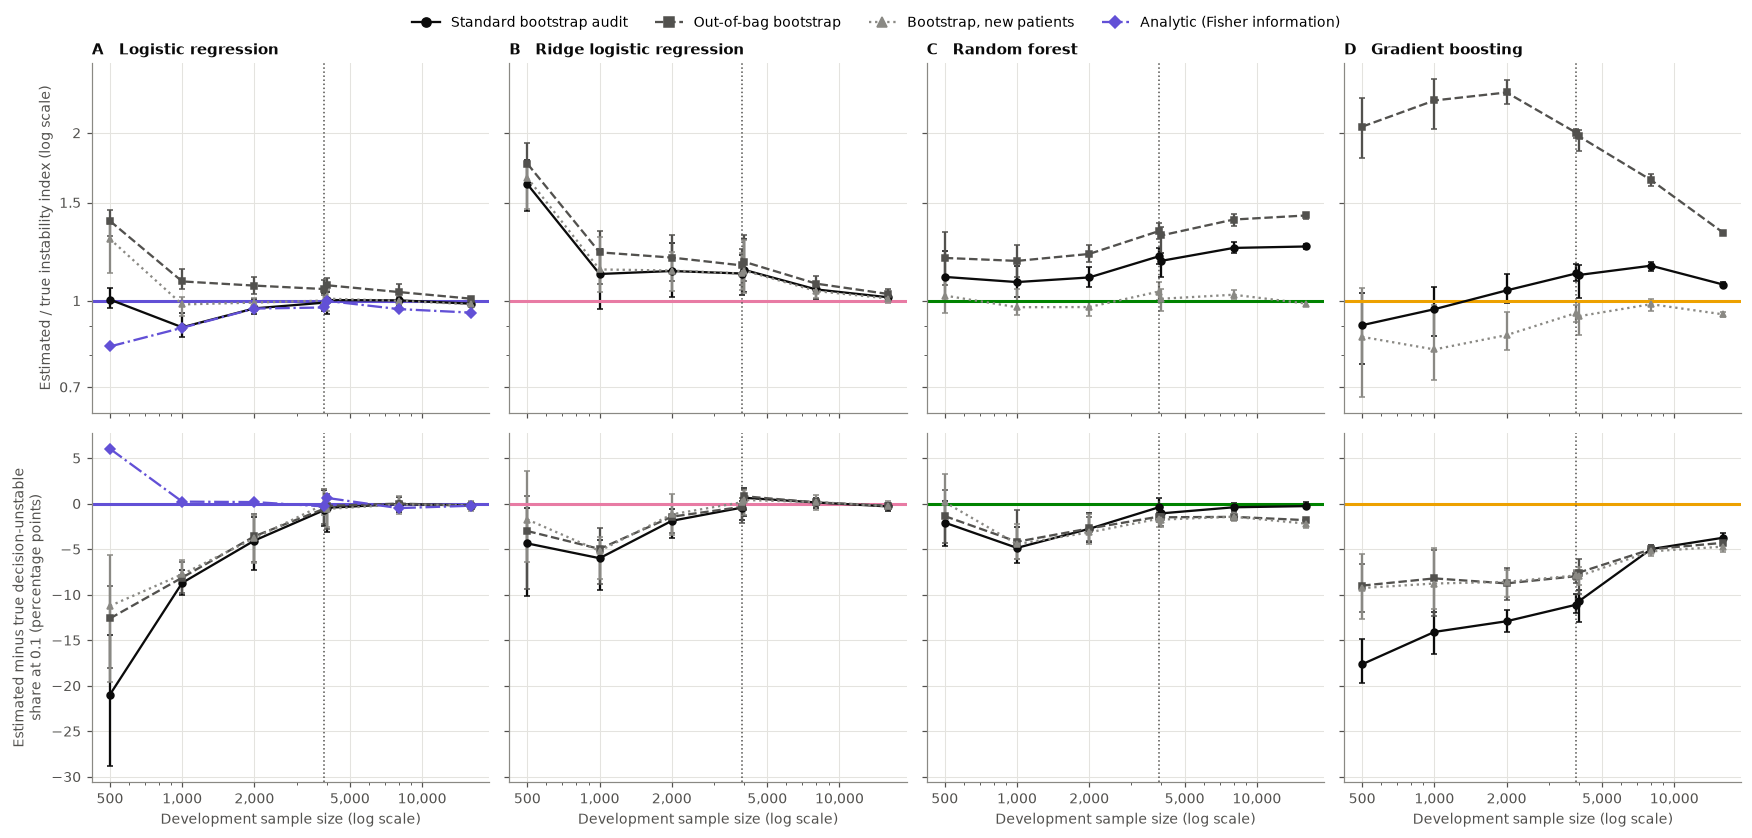

estimator                        analytic  bootstrap_new_patients  bootstrap_oob  bootstrap_standard
model                     n                                                                         
Gradient boosting         500         NaN                    0.86           2.05                0.90
                          1000        NaN                    0.82           2.29                0.97
                          2000        NaN                    0.87           2.36                1.04
                          3906        NaN                    0.95           2.00                1.12
                          4000        NaN                    0.94           1.97                1.11
                          8000        NaN                    0.99           1.65                1.16
                          16000       NaN                    0.94           1.32                1.07
Logistic regression       500        0.83                    1.29           1.39                1.00
                          1000       0.89                    0.98           1.08                0.90
                          2000       0.97                    0.99           1.06                0.97
                          3906       0.97                    1.00           1.05                0.99
                          4000       1.00                    1.01           1.07                1.00
                          8000       0.97                    1.00           1.04                1.00
                          16000      0.95                    0.99           1.01                0.99
Random forest             500         NaN                    1.02           1.19                1.10
                          1000        NaN                    0.97           1.18                1.08
                          2000        NaN                    0.97           1.21                1.10
                          3906        NaN                    1.04           1.33                1.20
                          4000        NaN                    1.01           1.31                1.18
                          8000        NaN                    1.02           1.40                1.24
                          16000       NaN                    0.99           1.42                1.25
Ridge logistic regression 500         NaN                    1.66           1.76                1.62
                          1000        NaN                    1.14           1.22                1.12
                          2000        NaN                    1.13           1.19                1.13
                          3906        NaN                    1.12           1.16                1.12
                          4000        NaN                    1.13           1.17                1.14
                          8000        NaN                    1.04           1.07                1.05
                          16000       NaN                    1.01           1.03                1.01

In [24]:
EST_STYLE = {"bootstrap_standard": dict(color=INK, marker="o", ls="-", label="Standard bootstrap audit"),
             "bootstrap_oob": dict(color=INK2, marker="s", ls="--", label="Out-of-bag bootstrap"),
             "bootstrap_new_patients": dict(color=NEUTRAL, marker="^", ls=":", label="Bootstrap, new patients"),
             "analytic": dict(color="#6250d6", marker="D", ls="-.", label="Analytic (Fisher information)")}
truth_idx = agg_truth.set_index(["model", "n"])
acc_rows = []
for (m, n, e), g in POP[POP["estimator"] != "truth"].groupby(["model", "n", "estimator"]):
    tr = truth_idx.loc[(m, n)]
    ratio = g["instability_index"] / tr["instability_index"]
    rms_ratio = g["rms_sd"] / tr["rms_sd"]
    diff = 100 * (g[f"share_unstable@{T0:g}"] - tr[f"share_unstable@{T0:g}"])
    acc_rows.append({"model": m, "n": n, "estimator": e, "ratio_mape": ratio.mean(), "ratio_mape_min": ratio.min(),
                     "ratio_mape_max": ratio.max(), "ratio_rms_sd": rms_ratio.mean(), "diff_unstable_pp": diff.mean(),
                     "diff_unstable_min": diff.min(), "diff_unstable_max": diff.max(),
                     "truth_mape": tr["instability_index"], "truth_unstable_pct": 100 * tr[f"share_unstable@{T0:g}"]})
ACC = pd.DataFrame(acc_rows)

fig, axes = plt.subplots(2, len(CONFIG["models"]), figsize=(4.0 * len(CONFIG["models"]), 7.4), sharex=True, sharey="row")
for j, m in enumerate(CONFIG["models"]):
    for e, style in EST_STYLE.items():
        g = ACC[(ACC["model"] == m) & (ACC["estimator"] == e)].sort_values("n")
        if g.empty:
            continue
        kw = dict(color=style["color"], marker=style["marker"], ls=style["ls"], markersize=4.5, lw=1.5)
        axes[0, j].errorbar(g["n"], g["ratio_mape"], yerr=[g["ratio_mape"] - g["ratio_mape_min"], g["ratio_mape_max"] - g["ratio_mape"]],
                            capsize=2, **kw)
        axes[1, j].errorbar(g["n"], g["diff_unstable_pp"], yerr=[g["diff_unstable_pp"] - g["diff_unstable_min"],
                                                                g["diff_unstable_max"] - g["diff_unstable_pp"]], capsize=2, **kw)
    axes[0, j].axhline(1, color=MODEL_COLORS[m], lw=2)
    axes[1, j].axhline(0, color=MODEL_COLORS[m], lw=2)
    axes[0, j].set_title(MODEL_LABELS[m], color=INK)
    for i in range(2):
        axes[i, j].set_xscale("log")
        plain_log_axis(axes[i, j].xaxis)
        if RILEY_IN:
            axes[i, j].axvline(N_RILEY, color=INK2, lw=1, ls=":")
    axes[1, j].set_xlabel("Development sample size (log scale)")
axes[0, 0].set_yscale("log")
plain_log_axis(axes[0, 0].yaxis, subs=(1.0, 1.5, 2.0, 3.0, 5.0, 7.0), fmt="{:g}")
axes[0, 0].set_ylabel("Estimated / true instability index (log scale)")
axes[1, 0].set_ylabel(f"Estimated minus true decision-unstable\nshare at {T0:g} (percentage points)")
for j, letter in enumerate("ABCD"[:len(CONFIG["models"])]):
    panel_label(axes[0, j], letter)
handles = [Line2D([0], [0], color=s["color"], marker=s["marker"], ls=s["ls"], lw=1.5, label=s["label"]) for s in EST_STYLE.values()]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save_figure(fig, "p2_fig7_estimator_accuracy", "Accuracy of instability estimators against independent-sample truth")

TABLE6 = ACC.assign(model=ACC["model"].map(MODEL_LABELS)).round(4)
save_table(TABLE6, "table6_estimator_accuracy", "Estimated versus true instability: ratio of instability index and difference in decision-unstable share")
display(TABLE6.pivot_table(index=["model", "n"], columns="estimator", values="ratio_mape").round(2))

### 7.7 Can the audit find the right patients? (Figure P2-8)

At the analytic minimum size (or the closest evaluated size): each audit patient's SD from bootstrap models applied to new patients (averaged over the R samples) against the true SD, in 20 bins of true SD, with the Spearman correlation across all patients. For the logistic model the analytic SD is added. Table 7 adds, at every size, the sensitivity and positive predictive value of the bootstrap flag ("decision-unstable") for truly decision-unstable patients.

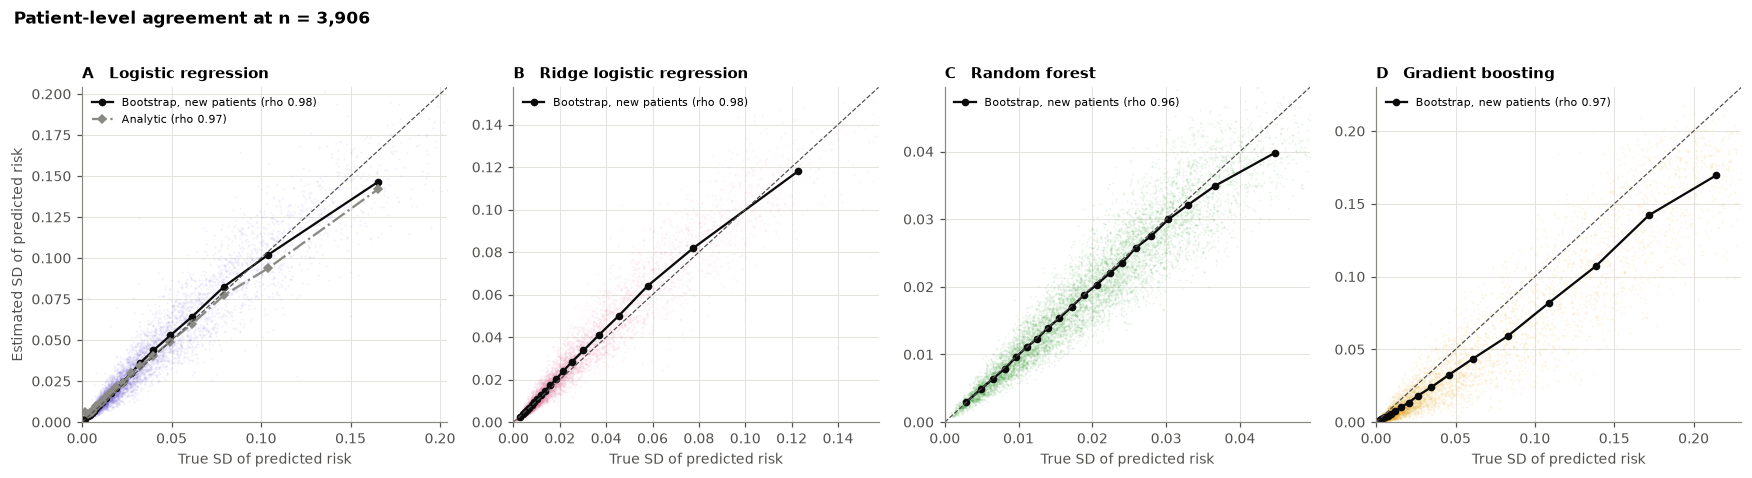

,model,n,truly_unstable,flagged,sensitivity,ppv,spearman_sd
0,Gradient boosting,500,2756.0,1969.2,0.583,0.817,0.794
1,Gradient boosting,1000,2250.0,1511.6,0.549,0.820,0.844
2,Gradient boosting,2000,2105.0,1389.0,0.568,0.862,0.891
3,Gradient boosting,3906,2196.0,1528.8,0.594,0.853,0.924
4,Gradient boosting,4000,2182.0,1511.2,0.589,0.851,0.920
5,Gradient boosting,8000,2079.0,1622.4,0.658,0.843,0.954
6,Gradient boosting,16000,1834.0,1421.2,0.689,0.890,0.975
7,Logistic regression,500,4320.0,3131.6,0.600,0.829,0.633
8,Logistic regression,1000,3584.0,2786.4,0.616,0.792,0.792
9,Logistic regression,2000,2625.0,2234.8,0.653,0.767,0.886


In [25]:
N_FOCUS = N_RILEY if RILEY_IN else SIZES[len(SIZES) // 2]


def binned_xy(x, y, n_bins=20):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    cnt = np.maximum(np.bincount(b, minlength=len(edges) - 1), 1)
    return np.bincount(b, weights=x, minlength=len(edges) - 1) / cnt, np.bincount(b, weights=y, minlength=len(edges) - 1) / cnt


fig, axes = plt.subplots(1, len(CONFIG["models"]), figsize=(4.0 * len(CONFIG["models"]), 4.2))
for ax, m, letter in zip(axes, CONFIG["models"], "ABCD"):
    true_sd = TRUTH[(m, N_FOCUS)]["s"]["sd"]
    boot_sd = np.mean([BOOT[(m, N_FOCUS, r)]["new"]["sd"] for r in range(CONFIG["r_boot"])], axis=0)
    rho = pd.Series(true_sd).corr(pd.Series(boot_sd), method="spearman")
    xb, yb = binned_xy(true_sd, boot_sd)
    ax.scatter(true_sd, boot_sd, s=2, alpha=0.08, color=MODEL_COLORS[m], lw=0, rasterized=True)
    ax.plot(xb, yb, color=INK, marker="o", markersize=4, lw=1.5, label=f"Bootstrap, new patients (rho {rho:.2f})")
    if m == "lr":
        an_sd = analytic_summary(N_FOCUS)["sd"]
        xa, ya = binned_xy(true_sd, an_sd)
        rho_a = pd.Series(true_sd).corr(pd.Series(an_sd), method="spearman")
        ax.plot(xa, ya, color=NEUTRAL, marker="D", markersize=4, lw=1.5, ls="-.", label=f"Analytic (rho {rho_a:.2f})")
    hi = float(np.quantile(np.concatenate([true_sd, boot_sd]), 0.995))
    ax.plot([0, hi], [0, hi], color=INK2, lw=0.8, ls="--")
    ax.set_xlim(0, hi)
    ax.set_ylim(0, hi)
    ax.set_xlabel("True SD of predicted risk")
    ax.set_title(MODEL_LABELS[m])
    ax.legend(fontsize=7, loc="upper left")
    panel_label(ax, letter)
axes[0].set_ylabel("Estimated SD of predicted risk")
fig.suptitle(f"Patient-level agreement at n = {N_FOCUS:,}", x=0.01, ha="left", y=1.02, fontweight="bold")
fig.tight_layout()
save_figure(fig, "p2_fig8_patient_level_agreement", "Patient-level agreement between bootstrap-estimated and true instability")

flag_rows = []
for m in CONFIG["models"]:
    for n in SIZES:
        truly = TRUTH[(m, n)]["s"][f"minority@{T0:g}"] > CONFIG["unstable_share"]
        for r in range(CONFIG["r_boot"]):
            est = BOOT[(m, n, r)]["new"]
            flag = est[f"minority_emp@{T0:g}"] > CONFIG["unstable_share"]
            tp = int((flag & truly).sum())
            flag_rows.append({"model": MODEL_LABELS[m], "n": n, "replicate": r, "truly_unstable": int(truly.sum()),
                              "flagged": int(flag.sum()), "sensitivity": tp / max(int(truly.sum()), 1),
                              "ppv": tp / max(int(flag.sum()), 1),
                              "spearman_sd": pd.Series(TRUTH[(m, n)]["s"]["sd"]).corr(pd.Series(est["sd"]), method="spearman")})
TABLE7 = pd.DataFrame(flag_rows).groupby(["model", "n"]).mean(numeric_only=True).drop(columns="replicate").reset_index()
save_table(TABLE7.round(4), "table7_flagging_accuracy", "Accuracy of bootstrap flags for truly decision-unstable patients")
display(TABLE7.round(3))

### 7.8 One patient, many possible models (Figure P2-9)

Six audit patients chosen before the experiment (full-sample logistic risk closest to 2, 5, 10, 15, 25 and 45%). Bands: 5th to 95th percentile of the risk each patient would have been given by the K independently developed models at each size; line: median. Dashed line: primary threshold.

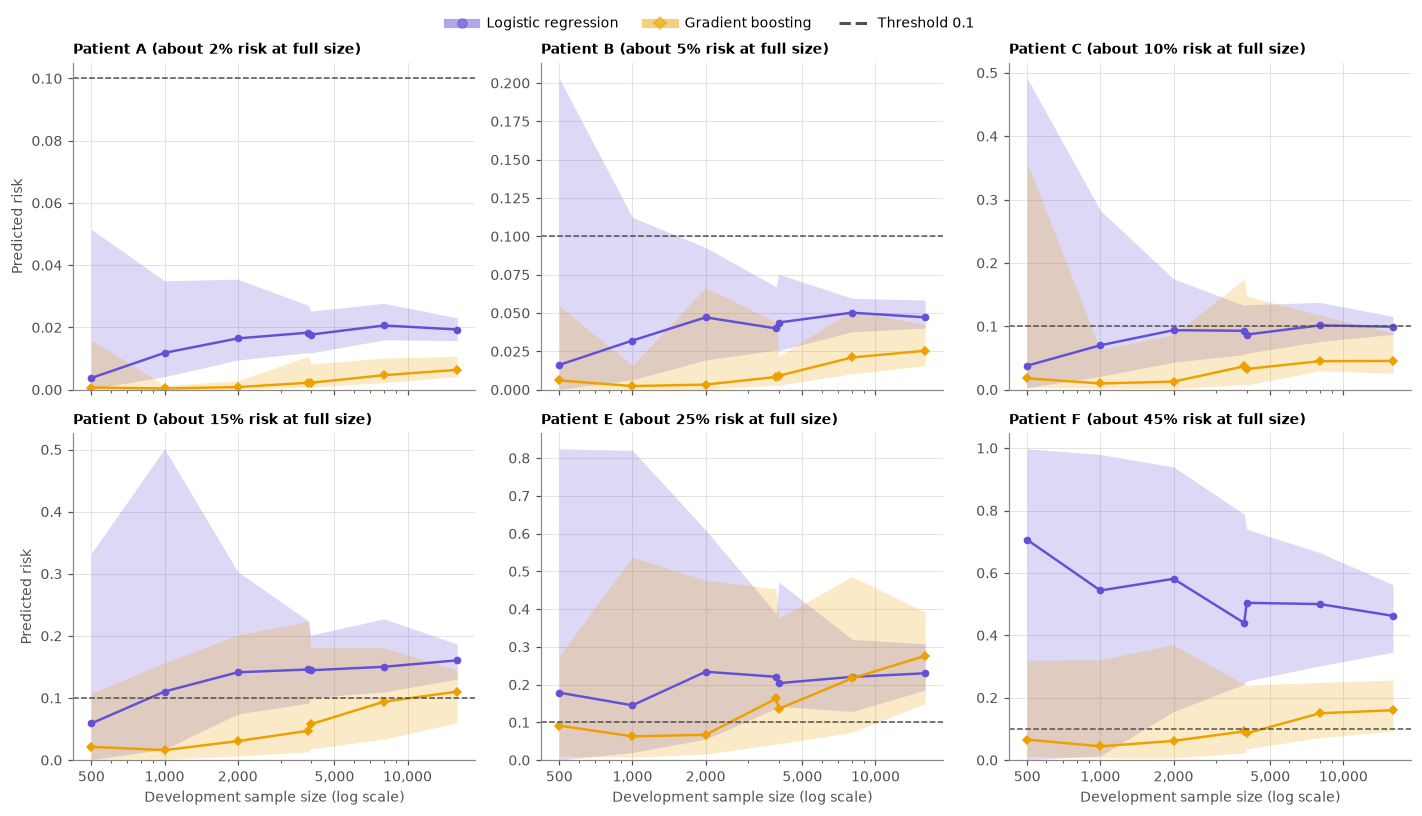

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True)
show_models = [m for m in ("lr", "hgb", "rf", "ridge") if m in CONFIG["models"]][:2]
for ax, ex, target, letter in zip(axes.ravel(), EXEMPLARS, EXEMPLAR_TARGETS, "ABCDEF"):
    for m in show_models:
        vals = np.array([TRUTH[(m, n)]["T_aud"][:, ex] for n in SIZES], dtype=float)
        lo, med, hi = np.quantile(vals, [0.05, 0.5, 0.95], axis=1)
        ax.fill_between(SIZES, lo, hi, color=MODEL_COLORS[m], alpha=0.22, lw=0)
        ax.plot(SIZES, med, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=4, lw=1.6)
    ax.axhline(T0, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis)
    ax.set_ylim(0, None)
    ax.set_title(f"Patient {letter} (about {100 * target:.0f}% risk at full size)", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Development sample size (log scale)")
for ax in axes[:, 0]:
    ax.set_ylabel("Predicted risk")
fig.legend(handles=[Line2D([0], [0], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], lw=6, alpha=0.5, label=MODEL_LABELS[m])
                    for m in show_models] + [Line2D([0], [0], color=INK2, ls="--", label=f"Threshold {T0:g}")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save_figure(fig, "p2_fig9_exemplar_patients", "Range of risks six patients would receive from independently developed models")

### 7.9 Equity of instability across sample sizes (Figure P2-10)

Risk-standardised instability ratio (true MAPE) for every subgroup on the audit panel at every size. Blue: more stable than the patient's risk level predicts; red: less stable. A gap that closes as n grows indicates instability caused by data scarcity in that subgroup; a gap that persists indicates a structural problem that more data from the same source will not fix.

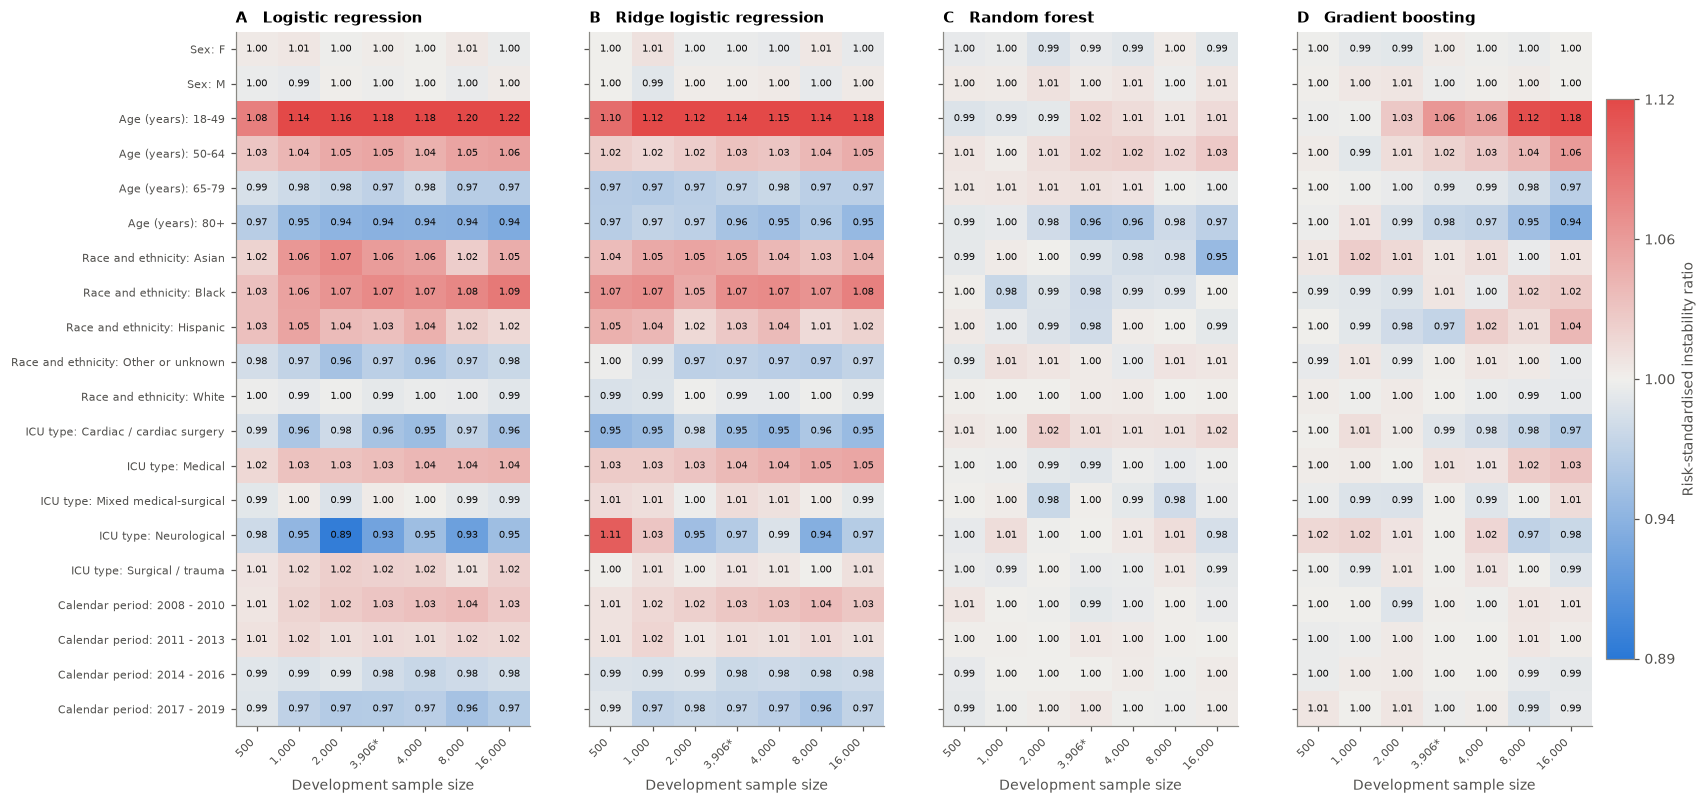

In [27]:
EQ = []
for m in CONFIG["models"]:
    for n in SIZES:
        s = TRUTH[(m, n)]["s"]
        t = risk_standardised(s["mape"], s["mean"], aud_frame, n_boot=0)
        EQ.append(t.assign(model=m, n=n))
EQ = pd.concat(EQ, ignore_index=True)
save_table(EQ.round(5), "tableS_p2_equity_by_size", "Risk-standardised instability ratio by subgroup, model and development size")

rows_lab = EQ[(EQ["model"] == CONFIG["models"][0]) & (EQ["n"] == SIZES[0])][["dimension", "level"]]
row_keys = list(zip(rows_lab["dimension"], rows_lab["level"]))
vmax = float(np.nanquantile(np.abs(np.log(EQ["ratio"])), 0.98))
fig, axes = plt.subplots(1, len(CONFIG["models"]), figsize=(3.6 * len(CONFIG["models"]) + 2, 0.32 * len(row_keys) + 1.8), sharey=True)
for ax, m, letter in zip(np.atleast_1d(axes), CONFIG["models"], "ABCD"):
    piv = EQ[EQ["model"] == m].pivot_table(index=["dimension", "level"], columns="n", values="ratio").reindex(row_keys)
    im = ax.imshow(np.log(piv.to_numpy()), cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(piv.to_numpy()):
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
    ax.set_xticks(range(len(SIZES)))
    ax.set_xticklabels([size_label(n) for n in SIZES], rotation=45, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(row_keys)))
    ax.set_yticklabels([f"{d}: {l}" for d, l in row_keys], fontsize=7.5)
    ax.grid(False)
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
    ax.set_xlabel("Development sample size")
cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
ticks = np.exp(np.linspace(-vmax, vmax, 5))
cbar.set_ticks(np.log(ticks))
cbar.set_ticklabels([f"{t:.2f}" for t in ticks])
cbar.set_label("Risk-standardised instability ratio")
save_figure(fig, "p2_fig10_equity_by_sample_size", "Risk-standardised instability ratio by subgroup and development size")

## 8. How much data does a stable individual prediction need? (Table 8)

Three pre-specified targets, each evaluated on the true instability curves (log-log interpolation between evaluated sizes; power-law extrapolation from the three largest sizes when a target is not reached, flagged). For the logistic model the analytic prediction is added. The **instability decay exponent** is the slope of log(RMS SD) on log(n): 0.5 is the parametric rate; smaller values mean that more data buys less stability.

| Target | Definition |
|---|---|
| T1 | Instability index (mean MAPE) of at most 1 percentage point |
| T2 | 90% of patients have a 95% uncertainty interval narrower than 10 percentage points |
| T3 | At most 5% of patients are decision-unstable at the primary threshold |

In [28]:
TARGETS = {"T1": ("instability_index", 0.01), "T2": ("width95_p90", 0.10), "T3": (f"share_unstable@{T0:g}", 0.05)}
EXTRAPOLATION_CAP = 1_000_000


def required_n(ns, vals, target):
    ns, vals = np.asarray(ns, float), np.asarray(vals, float)
    ok = vals <= target
    if ok.any():
        i = int(np.argmax(ok))
        if i == 0:
            return ns[0], "met at smallest size"
        v1, v2 = max(vals[i - 1], 1e-12), max(vals[i], 1e-12)
        if v2 <= 0 or v1 == v2:
            return ns[i], "interpolated"
        x = math.log(ns[i - 1]) + (math.log(target) - math.log(v1)) * (math.log(ns[i]) - math.log(ns[i - 1])) / (math.log(v2) - math.log(v1))
        return math.exp(x), "interpolated"
    k = min(3, len(ns))
    slope, intercept = np.polyfit(np.log(ns[-k:]), np.log(np.maximum(vals[-k:], 1e-12)), 1)
    if slope >= 0:
        return np.nan, "not reached (no decrease over the largest sizes)"
    n_req = math.exp((math.log(target) - intercept) / slope)
    if n_req > EXTRAPOLATION_CAP:
        return np.nan, f"beyond {EXTRAPOLATION_CAP:,} (extrapolation not reliable)"
    return n_req, "extrapolated"


req_rows = []
for m in CONFIG["models"]:
    t = agg_truth[agg_truth["model"] == m].sort_values("n")
    slope, intercept = np.polyfit(np.log(t["n"]), np.log(t["rms_sd"]), 1)
    resid = np.log(t["rms_sd"]) - (intercept + slope * np.log(t["n"]))
    se = math.sqrt(resid.var(ddof=2) / ((np.log(t["n"]) - np.log(t["n"]).mean()) ** 2).sum()) if len(t) > 2 else np.nan
    row = {"model": MODEL_LABELS[m], "source": "independent samples", "decay_exponent": -slope,
           "decay_exponent_lower": -slope - scipy.stats.t.ppf(0.975, max(len(t) - 2, 1)) * se,
           "decay_exponent_upper": -slope + scipy.stats.t.ppf(0.975, max(len(t) - 2, 1)) * se}
    for key, (col, target) in TARGETS.items():
        n_req, how = required_n(t["n"], t[col], target)
        row[f"{key}_n"] = n_req
        row[f"{key}_method"] = how
        row[f"{key}_times_minimum"] = n_req / N_RILEY if np.isfinite(n_req) else np.nan
    req_rows.append(row)
grid_n = np.unique(np.geomspace(100, 2_000_000, 400).astype(int))
an_curve = pd.DataFrame([{"n": n, **population_summary(analytic_summary(n))} for n in grid_n])
row = {"model": MODEL_LABELS["lr"], "source": "analytic (Fisher information)", "decay_exponent": 0.5}
for key, (col, target) in TARGETS.items():
    hit = an_curve.loc[an_curve[col] <= target, "n"]
    row[f"{key}_n"] = float(hit.iloc[0]) if len(hit) else np.nan
    row[f"{key}_method"] = "analytic" if len(hit) else "analytic: beyond 2,000,000"
    row[f"{key}_times_minimum"] = row[f"{key}_n"] / N_RILEY if len(hit) else np.nan
req_rows.append(row)
TABLE8 = pd.DataFrame(req_rows)
TABLE8.insert(1, "analytic_minimum_n", N_RILEY)
save_table(TABLE8.round(3), "table8_sample_size_for_stability",
           "Sample size needed for individual-level and decision-level stability versus the analytic minimum")
display(TABLE8.round(2))

,model,analytic_minimum_n,source,decay_exponent,decay_exponent_lower,decay_exponent_upper,T1_n,T1_method,T1_times_minimum,T2_n,T2_method,T2_times_minimum,T3_n,T3_method,T3_times_minimum
0,Logistic regression,3906,independent samples,0.52,0.48,0.57,30240.58,extrapolated,7.74,48864.97,extrapolated,12.51,121130.66,extrapolated,31.01
1,Ridge logistic regression,3906,independent samples,0.28,0.20,0.35,27100.23,extrapolated,6.94,54270.50,extrapolated,13.89,137556.20,extrapolated,35.22
2,Random forest,3906,independent samples,0.11,0.08,0.14,111862.80,extrapolated,28.64,127589.42,extrapolated,32.66,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN
3,Gradient boosting,3906,independent samples,0.14,0.11,0.17,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN
4,Logistic regression,3906,analytic (Fisher information),0.50,NaN,NaN,26631.00,analytic,6.82,42677.00,analytic,10.93,99244.00,analytic,25.41


## 9. Outputs for notebook 3, provenance and reporting

Notebook 3 reads `part2_summary.json`: the stored eICU-CRD predictions of every full-sample bootstrap model, and the eICU-CRD panel predictions of every independently developed and bootstrap model, so the external analyses need no refitting for the main questions.

In [29]:
headline = {}
for m, res in FULL_RES.items():
    s = population_summary(FULL_SPREAD[m])
    opt = res.optimism().set_index("metric")
    headline[m] = {"instability_index": s["instability_index"], "instability_index_oob": population_summary(FULL_OOB[m])["instability_index"],
                   "width95_median": s["width95_median"], "share_wide": s["share_wide"],
                   **{f"flip_prone_per_1000@{t:g}": 1000 * float(np.mean(FULL_SPREAD[m][f"cii@{t:g}"] > CONFIG["unstable_share"])) for t in THRESHOLDS},
                   "auroc_apparent": float(opt.loc["auroc", "apparent"]),
                   "auroc_optimism_corrected": float(opt.loc["auroc", "optimism_corrected"]),
                   "auroc_oob": float(opt.loc["auroc", "oob_mean"]),
                   "auroc_632plus": float(opt.loc["auroc", "estimate_632plus"]),
                   "calibration_slope_optimism_corrected": float(opt.loc["calibration_slope", "optimism_corrected"])}

PART2_SUMMARY = {
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "preset": PRESET, "preset_key": PRESET_KEY, "config": {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()},
    "models": CONFIG["models"], "model_labels": MODEL_LABELS, "thresholds": list(THRESHOLDS), "primary_threshold": T0,
    "full_audit_files": {m: {k: str(p.relative_to(PROJECT)) for k, p in full_paths(m).items()} for m in CONFIG["models"]},
    "multiverse_cache": str(CACHE.relative_to(PROJECT)), "multiverse_design": f"outputs/part2/data/multiverse_design_{PRESET_KEY}.json",
    "sizes": SIZES, "n_riley": N_RILEY, "exemplar_audit_positions": EXEMPLARS, "headline_full_sample": headline,
    "sample_size_targets": TABLE8.to_dict(orient="records"),
}
save_json(PART2_SUMMARY, "part2_summary", "Settings, file locations and headline results for notebook 3")
manifest = PROV.save({"config": PART2_SUMMARY["config"]})
print("Provenance manifest:", manifest)
print("Final chain hash:   ", PROV.chain)
display(pd.DataFrame(PROV.steps))
display(pd.DataFrame(headline).T.round(4))

Provenance manifest: C:\Users\kruta\Downloads\outputs\part2\logs\provenance_manifest.json
Final chain hash:    37bb5cee362d8a6b6c21ed3ba31f3aaec31d3919661dc5d138942063b2898bf2


,step,seconds
0,Full-sample audit: Logistic regression,0.3
1,Full-sample audit: Ridge logistic regression,0.3
2,Full-sample audit: Random forest,0.3
3,Full-sample audit: Gradient boosting,0.3
4,Multiverse experiment,2562.2


,instability_index,instability_index_oob,width95_median,share_wide,flip_prone_per_1000@0.1,flip_prone_per_1000@0.2,flip_prone_per_1000@0.3,auroc_apparent,auroc_optimism_corrected,auroc_oob,auroc_632plus,calibration_slope_optimism_corrected
lr,0.0083,0.0084,0.0208,0.1122,76.2648,48.6914,32.2774,0.8559,0.8533,0.8514,0.8530,0.9850
ridge,0.0079,0.0079,0.0203,0.1034,74.9887,47.2402,30.9513,0.8559,0.8535,0.8520,0.8534,0.9991
rf,0.0150,0.0173,0.0442,0.1976,133.3133,105.3395,70.5600,0.9549,0.9128,0.8716,0.8985,1.4874
hgb,0.0238,0.0263,0.0376,0.3064,152.3295,121.2030,98.6839,0.9352,0.8999,0.8794,0.8982,1.0205


### Reporting checklist coverage (TRIPOD+AI)

| Item | Where |
|---|---|
| 12a-12e: model building, preprocessing, model types, hyperparameters, handling of missing data inside the pipeline | Sections 0 and 3; model specification table |
| 12f: internal validation | Section 5, Table 2 (Harrell, OOB, .632+) |
| 13: class imbalance not altered; no resampling to balance outcomes | Section 0 |
| 14: fairness, performance and stability in subgroups | Sections 6 and 7.9; Table 4; Figures P2-5 and P2-10 |
| 16: model output (risks) and thresholds | Section 0; Figures P2-3 and P2-S2 |
| 22, 23a: full model specification, model performance | Model equation tables; Table 2 |
| 23b: uncertainty and stability of individual predictions | Table 3; Figures P2-2 to P2-4; section 7 |
| 10: sample size | Section 7.1 and Table 8 |

### Checks before notebook 3

1. Every full-sample audit reports 0 failed replicates (or very few) and the bootstrap rows were regenerated and verified.
2. Table S (finite-population correction check): ratios close to 1 support the corrected truth at large sizes.
3. Table 6 and Figure P2-7: note for each model whether the standard audit over- or under-states instability; these estimates are carried to the external hospitals in notebook 3.
4. The headline table above is the source for the abstract's development results.